# Predicting Client Enrollment in a Financial Marketing Campaign

This project uses historical marketing campaign data from a financial institution, containing 41,188 observations and 16 predictors (client demographics, financial characteristics, previous marketing interactions, and macroeconomic indicators such as CPI and CCI) and a binary enrollment outcome.

Our goal is to answer the question: **How can a financial institution use predictive modeling to improve the efficiency of its marketing campaigns?**

We develop machine learning models to predict the likelihood of a client enrolling in a financial product. We explore and compare several approaches, including **Logistic Regression**, **Decision Tree**, **Random Forest**, **Gradient Boosting**, and **HistGradientBoosting**.

We prioritize Average Precision (AP) for model selection because of the class imbalance in the data and evaluate performance using ROC-AUC, F1-score, and other metrics.

**Key Results.** HistGradientBoosting achieved the highest cross-validated AP (**0.461**) among the tuned models and was selected as the final model, although the strongest ensemble models performed similarly overall. On the test set, HistGradientBoosting achieved an AP of **0.475** (random baseline: 0.113), a ROC-AUC of **0.805**, and an F1-score of **0.518** at the threshold selected from out-of-fold predictions.

**Data Dictionary Note.** The provided data dictionary states that `number_days_since_last = 999` means that the client had no prior contact. However, as shown in Section 1.4.2, among the 31,724 training observations with `number_days_since_last = 999`, 3,308 (10.4%) have `number_contacts_previous > 0`, indicating that these clients had been contacted before.



### Report Organization

1. **Data Preparation and Exploratory Data Analysis:** 1.1 Data Preparation and Quality Checks; 1.2 Train/Test Split; 1.3 Validation Strategy; 1.4 Exploratory Data Analysis; 1.5 Feature Engineering & Preprocessing.

2. **Predictive Modeling and Key Findings:** 2.1 Metric Choice; 2.2 Logistic Regression Baseline; 2.3 Model Comparison; 2.4 Hyperparameter Tuning; 2.5 Overfitting Check; 2.6 Threshold Selection; 2.7 Final Model Evaluation; 2.8 Robustness Checks; 2.9 Feature Importance and Feature Relationships; 2.10 Why Is This Approach Suitable?

3. **Business Recommendations:** 3.1 Targeting Strategy: Who Should Be Targeted?; 3.2 Expected Campaign Lift: How Much Improvement Can Model-Based Targeting Provide?; 3.3 Deployment and Campaign Testing: How Should the Model Be Used and Tested in Future Campaigns?

4. **Limitations:** 4.1 Feature Availability at Prediction Time; 4.2 Ambiguity in `number_days_since_last`; 4.3 Duplicate and Conflicting Observations; 4.4 Temporal Validation, Macroeconomic Regimes, and External Validity; 4.5 Historical Targeting and Population Selection Bias; 4.6 Model and Experiment Coverage; 4.7 Prediction vs. Incremental Campaign Impact; 4.8 Decision Threshold, Probability Calibration, and Business Costs; 4.9 Responsible Deployment: Fairness and Monitoring.

**Appendix:** A.1 Treatment of `"unknown"` Categories; A.2 Target Distribution; A.3 Economic Indicators and Enrollment; A.4 Detailed Enrollment Rates by Categorical Feature; A.5 Binned Analysis of Selected Numerical Features; A.6 Evaluation Metrics; A.7 Overfitting Safeguards; A.8 Full Feature Association Heatmap.

## **1. Data Preparation and Exploratory Data Analysis**

### 1.1 Data Preparation and Quality Checks
We first examine the overall structure and quality of the dataset. This includes reviewing the dataset size and feature types, inspecting the enrollment distribution to assess class imbalance, and checking for missing values, "unknown" categories, and duplicate records. The goal is to identify potential data quality issues and determine any preprocessing required before the train/test split.

#### 1.1.1 Import the data set

In [ ]:
import pandas as pd
df = pd.read_csv('data/data.csv')

#### 1.1.2 Initial data inspection
We inspect the data size and the overall structure.

In [2]:
print('Data overview')
print("Data dimension:", df.shape)
df.info()
df.head(10)

Data overview
Data dimension: (41188, 17)
<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 17 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   customer_age              41188 non-null  int64  
 1   occupation                41188 non-null  str    
 2   marital_status            41188 non-null  str    
 3   education_level           41188 non-null  str    
 4   credit_in_default         41188 non-null  str    
 5   housing_loan              41188 non-null  str    
 6   personal_loan             41188 non-null  str    
 7   contact_channel           41188 non-null  str    
 8   month                     41188 non-null  str    
 9   day_of_week               41188 non-null  str    
 10  number_contacts           41188 non-null  int64  
 11  number_days_since_last    41188 non-null  int64  
 12  number_contacts_previous  41188 non-null  int64  
 13  enroll_previous           4118

,customer_age,occupation,marital_status,education_level,credit_in_default,housing_loan,personal_loan,contact_channel,month,day_of_week,number_contacts,number_days_since_last,number_contacts_previous,enroll_previous,cpi,cci,enroll
0,56,homemaker,married,basic,no,no,no,phone,may,M,1,999,0,does_not_exist,93.994,-36.4,no
1,57,services,married,high_school,unknown,no,no,phone,may,M,1,999,0,does_not_exist,93.994,-36.4,no
2,37,services,married,high_school,no,yes,no,phone,may,M,1,999,0,does_not_exist,93.994,-36.4,no
3,40,admin,married,basic,no,no,no,phone,may,M,1,999,0,does_not_exist,93.994,-36.4,no
4,56,services,married,high_school,no,no,yes,phone,may,M,1,999,0,does_not_exist,93.994,-36.4,no
5,45,services,married,basic,unknown,no,no,phone,may,M,1,999,0,does_not_exist,93.994,-36.4,no
6,59,admin,married,professional_training,no,no,no,phone,may,M,1,999,0,does_not_exist,93.994,-36.4,no
7,41,blue_collar,married,unknown,unknown,no,no,phone,may,M,1,999,0,does_not_exist,93.994,-36.4,no
8,24,technician,single,professional_training,no,yes,no,phone,may,M,1,999,0,does_not_exist,93.994,-36.4,no
9,25,services,single,high_school,no,yes,no,phone,may,M,1,999,0,does_not_exist,93.994,-36.4,no


The dataset contains both numerical and categorical features. Several categorical variables also include an `"unknown"` category, indicating potential data quality or missing-information issues that require further investigation before modeling.

#### 1.1.3 Inspect the overall data quality
We check the missing data, unknown values, and duplicate data.

In [3]:
#Check missing values
missing_summary = pd.DataFrame({
    "Number of Missing Values": df.isna().sum(),
    "Missing (%)": (df.isna().mean() * 100).round(2)
})
#Only present features with missing values
missing_summary = missing_summary[missing_summary["Number of Missing Values"]>0]
display(missing_summary)


,Number of Missing Values,Missing (%)


No missing values are present in the dataset; all variables have a missing rate of 0%.

In [4]:
# Check unknown values
unknown_summary = pd.DataFrame({
    "Number of Unknown": (df == "unknown").sum(),
    "Unknown (%)": (df == "unknown").mean() * 100
})
# Only present features with unknown values
unknown_summary = unknown_summary[unknown_summary["Number of Unknown"] > 0]
display(unknown_summary)

,Number of Unknown,Unknown (%)
occupation,330,0.801204
marital_status,80,0.194231
education_level,1731,4.202680
credit_in_default,8597,20.872584
housing_loan,990,2.403613
personal_loan,990,2.403613


Six categorical features contain `"unknown"` values. Most occur at relatively low rates (below 5%), but `credit_in_default` has a substantially higher unknown rate of 20.9%. Later we keep `"unknown"` as an explicit category and encode it together with the other categorical levels during one-hot encoding. See more discussion in the **Appendix**.

In [5]:
# Check duplicate records
n_duplicates = df.duplicated().sum()
print("Number of duplicate records:", n_duplicates)
print(f"Duplicate percentage: {n_duplicates / len(df) * 100:.2f}%")
# Separate features from enrollment outcome
feature_cols = df.columns.drop("enroll").tolist()
# Number of distinct enrollment outcomes per feature combination
target_counts = df.groupby(feature_cols)["enroll"].nunique()
# Identify groups with same features but different enrollment outcomes
conflicting_groups = target_counts[target_counts > 1]
print("Number of conflicting feature groups:", len(conflicting_groups))

Number of duplicate records: 2725
Duplicate percentage: 6.62%
Number of conflicting feature groups: 321


2,725 records (6.62%) are exact duplicates of an earlier record across all 17 columns. Exact duplication does not necessarily indicate data-entry errors since the dataset contains no unique client identifier such as user_id. Many features are coarse, so different clients can share identical attributes. 321 groups share identical predictor values but have different enrollment outcomes, indicating that identical profiles can correspond to different observations.

We therefore keep all observations rather than delete exact duplicates. Identical records may appear in both the training and test sets after random splitting, which could lead to somewhat optimistic test performance. We address this issue in section **2.8.1**.

### 1.2 Train/Test Split
We use an 80/20 stratified random split, with `enroll` as the stratification variable. The target is imbalanced, with an overall enrollment rate of approximately 11.27%. A simple random split does not guarantee that the training and test sets preserve this class distribution. Stratification ensures that both sets have nearly identical enrollment rates, providing a more stable and representative evaluation. The observations appear to be grouped by month in repeated calendar-like sequences, suggesting that the original row order may contain a temporal component. We considered a sequential 80/20 split using the original row order, but this produces a substantial difference in enrollment rates between the first 80% (6.37%) and the last 20% (30.83%). Given that the dataset does not include a year or a complete timestamp, we use the stratified random split as the primary evaluation strategy. If the data are temporally ordered, random splitting may introduce leakage by using future observations to predict earlier ones. See **Section 4** for further discussion.

In [6]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop(columns=["enroll"])
y = (df["enroll"] == "yes").astype(int)

# Stratified 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nOverall enrollment rate:", y.mean())
print("Training enrollment rate:", y_train.mean())
print("Test enrollment rate:", y_test.mean())


Training set: (32950, 16)
Test set: (8238, 16)

Overall enrollment rate: 0.11265417111780131
Training enrollment rate: 0.11265553869499241
Test enrollment rate: 0.11264870114105366


The stratified split preserves the overall enrollment rate almost exactly in both the training and test sets (11.27%).

In [7]:
# We observe that the data mighe be recorded in chronological order, so we also check the enrollment rate of first 80% and last 20%.
# Check enrollment rates across the original data order
split_idx = int(len(df) * 0.8)
first_80 = df.iloc[:split_idx]
last_20 = df.iloc[split_idx:]

enrollment_rates = pd.DataFrame({
    "Subset": ["First 80%", "Last 20%", "Overall"],
    "Samples": [len(first_80), len(last_20), len(df)],
    "Enrollment Rate": [
        first_80["enroll"].eq("yes").mean(),
        last_20["enroll"].eq("yes").mean(),
        df["enroll"].eq("yes").mean()
    ]
})

enrollment_rates["Enrollment Rate"] = (
    enrollment_rates["Enrollment Rate"].map("{:.2%}".format)
)

display(enrollment_rates)


,Subset,Samples,Enrollment Rate
0,First 80%,32950,6.37%
1,Last 20%,8238,30.83%
2,Overall,41188,11.27%


A sequential 80/20 split produces a large difference in enrollment rates, from 6.37% in the first 80% to 30.83% in the last 20%.

### 1.3 Validation Strategy
We use 5-fold stratified cross-validation on the training set for model selection and hyperparameter tuning. This preserves the class distribution across folds and provides a more robust estimate of model performance than a single validation split.

### 1.4 Exploratory Data Analysis
All exploratory analysis is performed on the training set only. This avoids using information from the test set when making modeling or feature-engineering decisions. We combine X_train and y_train into a separate DataFrame for EDA while leaving the original training data unchanged.

#### 1.4.1 Overview of the data

In [8]:
import numpy as np
# Create a separate DataFrame for EDA
train_eda = X_train.copy()
train_eda["enroll"] = np.asarray(y_train)
print("Training data dimension:", train_eda.shape)

Training data dimension: (32950, 17)


In [9]:
# Summary statistics
display(train_eda.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_age,32950.0,NaN,NaN,NaN,40.014112,10.403636,17.0,32.0,38.0,47.0,98.0
occupation,32950,12,admin,8314,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital_status,32950,4,married,19953,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education_level,32950,6,basic,10013,NaN,NaN,NaN,NaN,NaN,NaN,NaN
credit_in_default,32950,3,no,26007,NaN,NaN,NaN,NaN,NaN,NaN,NaN
housing_loan,32950,3,yes,17254,NaN,NaN,NaN,NaN,NaN,NaN,NaN
personal_loan,32950,3,no,27131,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact_channel,32950,2,email,20908,NaN,NaN,NaN,NaN,NaN,NaN,NaN
month,32950,10,may,11011,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day_of_week,32950,5,R,6857,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Initial observations:
1. **customer_age:** The median customer age is 38, and the middle 50% of the customers are between 32 and 47.
2. **number_contacts:** At least 75% of the customers are contacted between 1 and 3 times. The mean and maximum are 2.56 and 56 times, indicating a right-skewed distribution.
3. **numer_days_since_last:** At least 75% of the data is 999, suggesting that 999 is a special value rather than an actual number of days. We need further investigation.
4. **number_contacts_previous:** At least 75% of the data is 0 and the maximum is 7, indicating that the distribution is right-skewed.
5. **cpi and cci:** Both variables vary within relatively narrow ranges in this dataset.
6. **categorical features:** Several categorical variables are dominated by one category. For example, most customers have no recorded credit default, and most have no previous enrollment outcome.
7. **enroll (target):** The mean of `enroll` is approximately 0.113, confirming that only about 11.27% of customers enrolled and that the target is substantially imbalanced.

#### 1.4.2 The value 999

In [10]:
# Check the number and proportion of 999 values
n_999 = train_eda["number_days_since_last"].eq(999).sum()
pct_999 = train_eda["number_days_since_last"].eq(999).mean()
print("Number of 999 values:", n_999)
print(f"Proportion of 999 values: {pct_999:.2%}")

Number of 999 values: 31724
Proportion of 999 values: 96.28%


`number_days_since_last` contains 31,724 values equal to 999, representing 96.28% of the training data. This strongly suggests that 999 is a special code rather than an actual number of days and should be treated separately in later feature engineering.

In [11]:
anomaly = train_eda[(train_eda["number_days_since_last"] == 999) &
                    (train_eda["number_contacts_previous"] != 0)]

print(len(anomaly), f"({len(anomaly) / (train_eda['number_days_since_last'] == 999).sum():.1%} of 999 rows)")
print(anomaly["number_contacts_previous"].value_counts().sort_index())
anomaly[["number_days_since_last", "number_contacts_previous", "enroll_previous"]].head()

3308 (10.4% of 999 rows)
number_contacts_previous
1    2976
2     279
3      41
4      10
5       1
6       1
Name: count, dtype: int64


,number_days_since_last,number_contacts_previous,enroll_previous
26010,999,1,failure
40890,999,1,failure
41121,999,1,failure
39927,999,1,failure
29154,999,1,failure


The provided data dictionary defines `number_days_since_last = 999` as indicating that the client was not previously contacted. The training data do not fully support this interpretation. Among the 31,724 training observations coded as 999, **3,308 (10.4%) have `number_contacts_previous > 0`**, showing that these clients had in fact been contacted in a previous campaign. Most of these clients were contacted once (2,976), although the number of previous contacts ranges up to six. This suggests that 999 cannot be interpreted uniformly as "never contacted." In **1.5**, we divide observations with `999` into two groups.

#### 1.4.3 Numerical Features

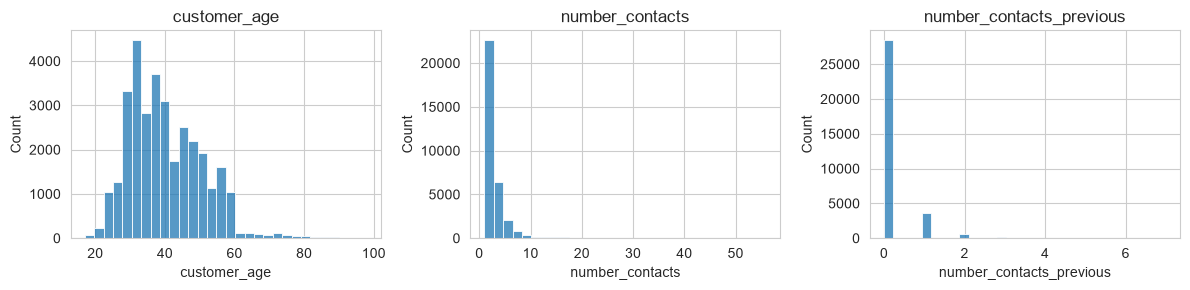

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
numerical_cols = [
    "customer_age",
    "number_contacts",
    "number_contacts_previous"
]
fig, axes = plt.subplots(1, 3, figsize=(12, 3))

for ax, col in zip(axes, numerical_cols):
    sns.histplot(
        data=train_eda,
        x=col,
        bins=30,
        ax=ax
    )
    ax.set_title(col)
    ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

`customer_age` has a relatively well-behaved distribution. However, enrollment varies nonlinearly with age, with higher rates among the youngest and oldest clients (Appendix A.5). The engineered feature set in Section 1.5 therefore adds `age_squared` while retaining the original age. `number_contacts` is strongly right-skewed, with most customers contacted only a few times but a maximum of **56 contacts**. The engineered feature set therefore adds `log_contacts = log1p(number_contacts)` to reduce the influence of the long right tail. `number_contacts_previous` is also concentrated near zero, but its range is much smaller, with a maximum of only **7 previous contacts**. The engineered feature set therefore retains the original count and adds an indicator for whether the customer had any prior campaign contact. These transformations are mainly expected to help linear models. Tree-based models are invariant to monotonic transformations such as `log1p`, and they can represent the prior-contact indicator with a single split. Whether the engineered features improve performance is evaluated in Section **2.3**.

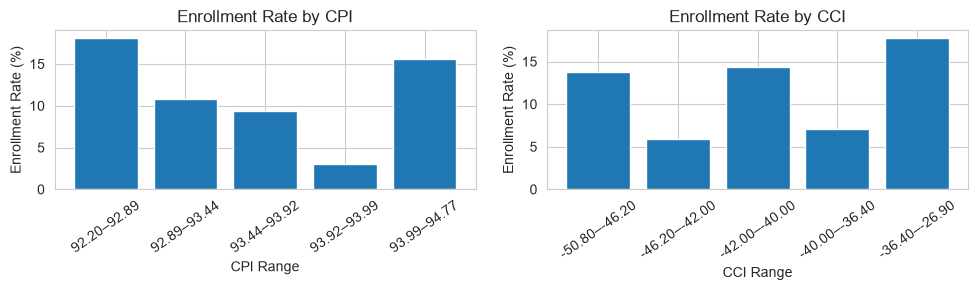

In [13]:
# Economic indicators and enrollment

fig, axes = plt.subplots(1, 2, figsize=(10, 3))

economic_summaries = []

for ax, col in zip(axes, ["cpi", "cci"]):

    bins = pd.qcut(
        train_eda[col],
        q=5,
        duplicates="drop"
    )

    summary = (
        train_eda.groupby(bins, observed=True)["enroll"]
        .agg(["mean", "size"])
    )

    # Save summary for the Appendix
    summary = summary.reset_index()
    summary.insert(0, "feature", col.upper())
    economic_summaries.append(summary)

    # Format interval labels
    labels = [
        f"{interval.left:.2f}–{interval.right:.2f}"
        for interval in summary[col]
    ]

    ax.bar(labels, summary["mean"] * 100)

    ax.set_title(f"Enrollment Rate by {col.upper()}")
    ax.set_xlabel(f"{col.upper()} Range")
    ax.set_ylabel("Enrollment Rate (%)")
    ax.tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

# Combined table retained for the Appendix
economic_indicator_summary = pd.concat(
    economic_summaries,
    ignore_index=True
)

 Enrollment rates vary substantially across both CPI and CCI ranges, but neither relationship is monotonic. For CPI, the enrollment rate is highest in the lowest range (18.1%), falls to only 3.0% around 93.92–93.99, and then rises again to 15.6% in the highest range. CCI shows a similar non-monotonic pattern, with enrollment rates ranging from 5.9% to 17.8%.
These patterns suggest that the effects of CPI and CCI may not be adequately captured by a simple linear relationship. Detailed bin-level results are provided in the **Appendix**.

#### 1.4.4 Categorical Features

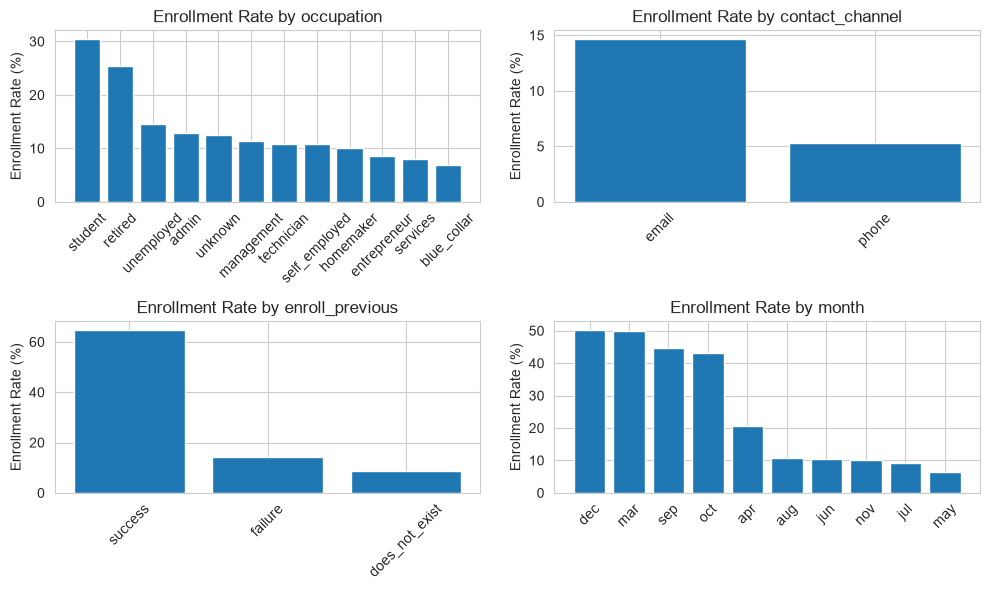

In [14]:
# Compare enrollment rates across selected categorical featureseda = train_eda.copy()
train_eda["enroll_binary"] = train_eda["enroll"]
categorical_cols = [
    "occupation",
    "contact_channel",
    "enroll_previous",
    "month"
]

fig, axes = plt.subplots(2, 2, figsize=(10, 6))

for ax, col in zip(axes.flat, categorical_cols):

    summary = (
        train_eda.groupby(col)["enroll_binary"]
        .agg(["mean", "size"])
        .sort_values("mean", ascending=False)
    )

    ax.bar(summary.index, summary["mean"] * 100)

    ax.set_title(f"Enrollment Rate by {col}")
    ax.set_ylabel("Enrollment Rate (%)")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

Enrollment rates vary substantially across several categorical features. Previous campaign outcome shows the strongest separation: clients with a previous successful enrollment have a much higher enrollment rate than those with a previous failure or no prior campaign outcome. Contact channel also shows a clear difference, with email contacts having a higher enrollment rate than phone contacts. Students and retired clients show relatively high enrollment rates, while blue-collar clients have lower rates. March, September, October, and December show substantially higher enrollment rates than most other months. Detailed enrollment-rate tables for each categorical feature are provided in the **Appendix**.

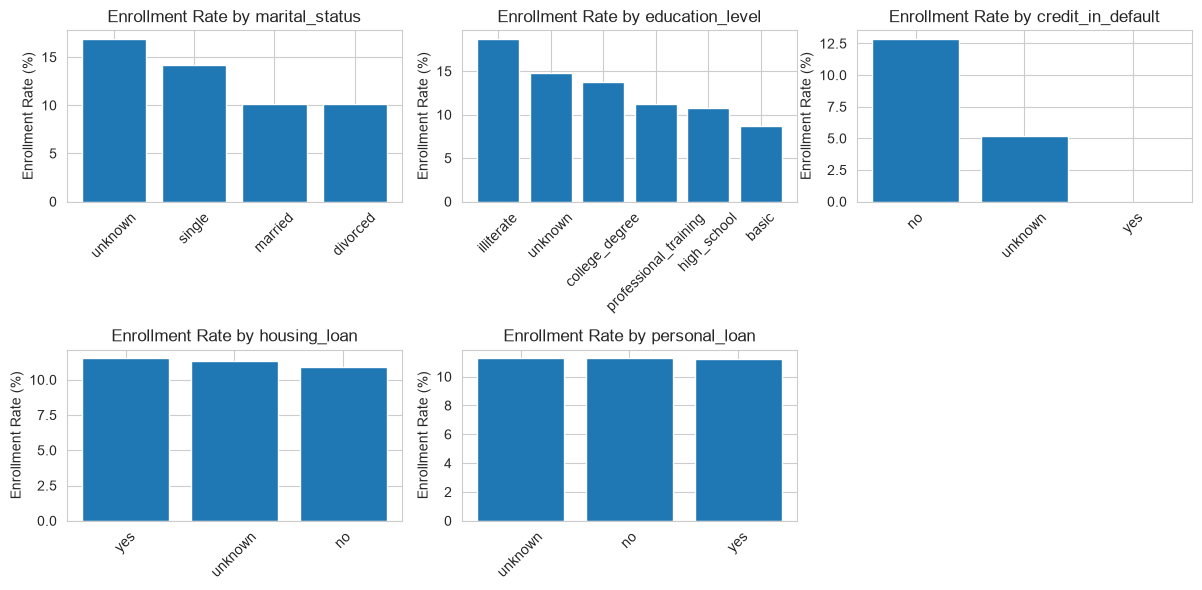

In [15]:
# Compare enrollment rates across additional categorical features
categorical_cols_2 = [
    "marital_status",
    "education_level",
    "credit_in_default",
    "housing_loan",
    "personal_loan"
]

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
axes = axes.flatten()

for ax, col in zip(axes, categorical_cols_2):
    summary = (
        train_eda.groupby(col)["enroll"]
        .agg(["mean", "size"])
        .sort_values("mean", ascending=False)
    )

    ax.bar(summary.index.astype(str), summary["mean"] * 100)
    ax.set_title(f"Enrollment Rate by {col}")
    ax.set_ylabel("Enrollment Rate (%)")
    ax.tick_params(axis="x", rotation=45)

# Hide the unused subplot
for ax in axes[len(categorical_cols_2):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

Enrollment rates vary across marital status and education level. Clients with unknown marital status and single clients show higher enrollment rates than married or divorced clients. For education level, illiterate clients have the highest enrollment rate, followed by clients with unknown education and those with a college degree. Credit default status shows a clearer difference: clients with no recorded default have a substantially higher enrollment rate than those with unknown default status, while the enrollment rate for clients in default is close to zero. Housing loan and personal loan status show a small variation in enrollment rates across categories. Detailed enrollment-rate tables for these categorical features are provided in the **Appendix**.

#### 1.4.5 Summary of EDA Findings
The EDA highlights several patterns that inform the subsequent feature engineering and modeling decisions:
1. **Class imbalance:** Only **11.27%** of clients enrolled, so model evaluation should not rely on accuracy alone.
2. **Numerical feature distributions:** `number_contacts` is strongly right-skewed, while `number_contacts_previous` is concentrated near zero. These patterns motivate transforming current contact frequency and explicitly representing prior contact history.
3. **Special value in previous-contact history:** `number_days_since_last = 999` appears in **96.28%** of the training data. Because 999 also occurs for clients with previous campaign contacts, it cannot be interpreted simply as “no previous contact” and requires separate treatment.
4. **Differences across categorical features:** Enrollment rates vary substantially across several categorical variables, particularly previous campaign outcome, contact channel, occupation, and campaign month. Housing and personal loan status show comparatively smaller differences.
5. **Potential nonlinear relationships:** Enrollment varies nonlinearly with age, contact frequency, CPI, and CCI. This suggests that purely linear relationships may not capture all of the predictive structure in the data.

### 1.5 Feature Engineering & Preprocessing

We construct two feature sets to evaluate whether additional feature engineering improves predictive performance. Both are generated by a single deterministic function, `create_features`, which has no fitted parameters and is applied identically to the training and test sets.

**Baseline Features (16 predictors)**

1. Keep the original predictors without additional nonlinear transformations.
2. Keep `"unknown"` as a separate categorical level (see Appendix **A.1**).
3. Replace `number_days_since_last` with a categorical recency feature, `contact_interval_group`. Actual day counts are grouped into `very_recent` (0–3 days), `within_the_week` (4–7), `within_two_weeks` (8–15), and `within_a_month` (16–27).
4. Split observations with `number_days_since_last = 999` into two separate levels, because 999 does not represent an actual number of days and cannot be interpreted uniformly as "never contacted" (Section **1.4.2**):
   1. `never_contacted`: `number_days_since_last = 999` and `number_contacts_previous = 0`.
   2. `un_retrievable`: `number_days_since_last = 999` and `number_contacts_previous > 0`.
5. Drop the original `number_days_since_last` column, so the number of predictors remains 16.

**Engineered Features (19 predictors)**

The baseline features plus:

1. `age_squared`, to capture a potential nonlinear relationship between age and enrollment while retaining the original age feature.
2. `log_contacts` = log(1 + `number_contacts`), to reduce the effect of its strong right skew while retaining the original contact count.
3. `has_prior_campaign_contact`, an indicator for `number_contacts_previous > 0`.

**Preprocessing**
Preprocessing is fitted separately within each training fold during cross-validation. Both feature sets use the same `ColumnTransformer` inside each modeling pipeline:

1. Numerical features are standardized with `StandardScaler`. Scaling does not affect tree-based models, but it is kept so that all models share one pipeline.
2. Categorical features are one-hot encoded with `OneHotEncoder(handle_unknown="ignore")`.


In [16]:
def create_features(X, engineered=False):
    X = X.copy()

    # Group time since previous campaign contact
    days = X["number_days_since_last"]

    X["contact_interval_group"] = pd.cut(
        days.where(days != 999),
        bins=[-np.inf, 3, 7, 15, 27],
        labels=[
            "very_recent",
            "within_the_week",
            "within_two_weeks",
            "within_a_month"
        ]
    ).astype("object").fillna("un_retrievable")

    X.loc[(days == 999) & (X["number_contacts_previous"] == 0),
      "contact_interval_group"] = "never_contacted"

    X = X.drop(columns=["number_days_since_last"])

    if engineered:
        X["age_squared"] = X["customer_age"] ** 2

        X["log_contacts"] = np.log1p(
            X["number_contacts"]
        )

        X["has_prior_campaign_contact"] = (
            X["number_contacts_previous"] > 0
        ).astype(int)

    return X

# Construct two feature sets from training data
X_train_baseline = create_features(X_train)

X_test_baseline = create_features(X_test)

X_train_engineered = create_features(
    X_train,
    engineered=True
)

print("Baseline:", X_train_baseline.shape)
print("Engineered:", X_train_engineered.shape)


Baseline: (32950, 16)
Engineered: (32950, 19)


The baseline feature set contains 16 predictors. `number_days_since_last` is replaced by the categorical `contact_interval_group`, so this transformation does not change the total number of predictors. The engineered feature set contains 19 predictors after adding `age_squared`, `log_contacts`, and `has_prior_campaign_contact`.

In [17]:
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Select columns by data type
numeric_selector = make_column_selector(dtype_include=np.number)
categorical_selector = make_column_selector(dtype_exclude=np.number)

# Preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_selector
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_selector
        )
    ],
    remainder="drop"
)

## 2. Predictive Modeling and Key Findings


### 2.1 Metric Choice

The target is imbalanced: only about **11.27%** of clients enroll in the product. Ordinary accuracy is therefore not used as the primary model-selection metric. For model comparison and hyperparameter tuning, we use **Average Precision (AP)** as the primary metric because it focuses on precision-recall performance and is well suited to an imbalanced classification problem. **ROC-AUC** is reported as a secondary threshold-independent metric. Threshold-based metrics, including Accuracy, Balanced Accuracy, Precision, Recall, and F1, are reported for descriptive purposes but are not used to select the best model. After the final model is selected based primarily on AP, its operating threshold is chosen using out-of-fold predictions from the training set to maximize **F1**. Detailed definitions and additional discussion of the evaluation metrics are provided in Appendix A.6.

### 2.2 Logistic Regression Baseline

We first use Logistic Regression as a **baseline**. Because the target is imbalanced, we set `class_weight="balanced"`, which assigns larger weights to the minority class during model fitting based on the observed class frequencies. We compare three benchmarks:
1. a Dummy Classifier representing a non-informative baseline,
2. Logistic Regression with the baseline feature set, and
3. Logistic Regression with the engineered feature set.

In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.base import clone
from sklearn.metrics import (make_scorer, precision_score, recall_score, f1_score)

# 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluation metrics
scoring = {
    "Accuracy": "accuracy",
    "Balanced Accuracy": "balanced_accuracy",
    "Precision": make_scorer(precision_score, zero_division=0),
    "Recall": make_scorer(recall_score, zero_division=0),
    "F1": make_scorer(f1_score, zero_division=0),
    "AP": "average_precision",
    "ROC-AUC": "roc_auc"
}

# Dummy classifier: always predicts the majority class
dummy = DummyClassifier(strategy="prior")

# Logistic Regression pipeline
lr_pipeline = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

# Models to compare
models = {
    "Dummy (Majority Class)": (dummy, X_train_baseline),
    "LR - Baseline": (lr_pipeline, X_train_baseline),
    "LR - Engineered": (lr_pipeline, X_train_engineered)
}

# Cross-validation
results = []

for name, (model, X_features) in models.items():

    scores = cross_validate(
        model,
        X_features,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    row = {"Model": name}

    for metric in scoring:
        values = scores[f"test_{metric}"]

        row[metric] = (
            f"{values.mean():.4f} ± {values.std():.4f}"
        )

    results.append(row)

cv_results = pd.DataFrame(results)

display(cv_results)


,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1,AP,ROC-AUC
0,Dummy (Majority Class),0.8873 ± 0.0001,0.5000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.1127 ± 0.0001,0.5000 ± 0.0000
1,LR - Baseline,0.8139 ± 0.0051,0.7140 ± 0.0036,0.3213 ± 0.0072,0.5851 ± 0.0081,0.4147 ± 0.0059,0.3973 ± 0.0095,0.7670 ± 0.0040
2,LR - Engineered,0.8155 ± 0.0051,0.7166 ± 0.0028,0.3245 ± 0.0064,0.5889 ± 0.0104,0.4184 ± 0.0041,0.3989 ± 0.0096,0.7691 ± 0.0029


The Dummy Classifier achieves an AP of **0.1127**, close to the positive-class prevalence, and a ROC-AUC of **0.5000**, as expected for a non-informative baseline. Both Logistic Regression models perform substantially better. The baseline feature set achieves an AP of **0.3973 ± 0.0095** and ROC-AUC of **0.7670 ± 0.0040**, while the engineered feature set reaches **0.3989 ± 0.0096** and **0.7691 ± 0.0029**, respectively. The engineered features therefore provide only a **small improvement** over the baseline features. The differences in AP and ROC-AUC are also small relative to the variation across cross-validation folds, so there is no strong evidence at this stage that feature engineering materially improves Logistic Regression performance.

### 2.3 Model Comparison

We compare the baseline with **Logistic Regression, Decision Tree, Random Forest, and Gradient Boosting** to determine whether nonlinear relationships and feature interactions provide additional predictive value.

> **Note.** The initial nonlinear model comparison considers three standard tree-based models: Decision Tree, Random Forest, and Gradient Boosting. After hyperparameter tuning, we add HistGradientBoosting as an additional candidate and evaluate it using the same validation framework.

In [19]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

# Candidate models
candidate_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

# Feature sets
feature_sets = {
    "Baseline": X_train_baseline,
    "Engineered": X_train_engineered
}

# Model comparison
results = []

for model_name, model in candidate_models.items():

    for feature_name, X_features in feature_sets.items():

        pipeline = Pipeline([
            ("preprocessing", clone(preprocessor)),
            ("model", clone(model))
        ])

        scores = cross_validate(
            pipeline,
            X_features,
            y_train,
            cv=cv,
            scoring=scoring,
            n_jobs=2
        )

        row = {
            "Model": model_name,
            "Features": feature_name
        }

        for metric in scoring:
            values = scores[f"test_{metric}"]

            row[metric] = values.mean()
            row[f"{metric} Std"] = values.std()

        results.append(row)

model_results = pd.DataFrame(results)

# Display the main comparison metrics
display(
    model_results[
        [
            "Model",
            "Features",
            "AP",
            "AP Std",
            "ROC-AUC",
            "ROC-AUC Std",
            "Precision",
            "Recall",
            "F1"
        ]
    ].round(4)
)

,Model,Features,AP,AP Std,ROC-AUC,ROC-AUC Std,Precision,Recall,F1
0,Logistic Regression,Baseline,0.3973,0.0095,0.7670,0.0040,0.3213,0.5851,0.4147
1,Logistic Regression,Engineered,0.3989,0.0096,0.7691,0.0029,0.3245,0.5889,0.4184
2,Decision Tree,Baseline,0.3848,0.0117,0.7633,0.0036,0.3187,0.6191,0.4145
3,Decision Tree,Engineered,0.3848,0.0117,0.7633,0.0036,0.3187,0.6191,0.4145
4,Random Forest,Baseline,0.4502,0.0111,0.7841,0.0031,0.3834,0.6029,0.4687
5,Random Forest,Engineered,0.4480,0.0112,0.7818,0.0037,0.3867,0.6021,0.4710
6,Gradient Boosting,Baseline,0.4530,0.0159,0.7922,0.0043,0.6628,0.2007,0.3077
7,Gradient Boosting,Engineered,0.4529,0.0160,0.7922,0.0043,0.6623,0.2007,0.3076


Gradient Boosting achieves the strongest overall cross-validation performance, with the highest **AP (0.4530)** and **ROC-AUC (0.7922)**. Random Forest performs similarly, reaching an AP of approximately **0.450**, while both ensemble methods clearly outperform Logistic Regression and the single Decision Tree on the primary metric. The engineered features provide only marginal improvement for Logistic Regression and essentially no improvement for the tree-based models. This is expected because tree-based methods can capture nonlinear relationships and interactions directly from the original features. Although Gradient Boosting has relatively low Recall and F1-score at the default classification threshold, these threshold-dependent metrics are not used for model selection at this stage. Based on these results, the three tree-based models are carried forward to hyperparameter tuning in **2.4**, with Gradient Boosting and Random Forest currently showing the strongest predictive performance.

### 2.4 Hyperparameter Tuning

In [20]:
from sklearn.model_selection import RandomizedSearchCV

# Hyperparameter search spaces
param_grids = {

    "Decision Tree": {
        "model__max_depth": [None, 3, 5, 10, 20],
        "model__min_samples_split": [2, 5, 10, 20],
        "model__min_samples_leaf": [1, 3, 5, 10, 20],
        "model__max_features": [None, "sqrt", 0.5],
        "model__criterion": ["gini", "entropy"]
    },

    "Random Forest": {
        "model__n_estimators": [100, 200, 300],
        "model__max_depth": [None, 10, 20],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 3, 5],
        "model__max_features": ["sqrt", 0.5]
    },

    "Gradient Boosting": {
        "model__n_estimators": [100, 150, 200],
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__max_depth": [2, 3],
        "model__min_samples_leaf": [5, 10, 20],
        "model__subsample": [0.8, 1.0]
    }
}

# Store tuning results and fitted search objects
tuning_results = []
tuned_models = {}

for name in [
    "Decision Tree",
    "Random Forest",
    "Gradient Boosting"
]:

    pipeline = Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("model", clone(candidate_models[name]))
    ])

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=param_grids[name],
        n_iter=15,
        scoring=scoring,
        refit="AP",
        cv=cv,
        random_state=42,
        n_jobs=2,
        verbose=1
    )

    search.fit(X_train_baseline, y_train)

    tuned_models[name] = search.best_estimator_

    best_idx = search.best_index_

    tuning_results.append({
        "Model": name,
        "Best CV AP": search.best_score_,
        "CV ROC-AUC": search.cv_results_[
            "mean_test_ROC-AUC"
        ][best_idx],
        "Best Parameters": search.best_params_
    })

tuning_results = pd.DataFrame(tuning_results)

display(tuning_results)

Fitting 5 folds for each of 15 candidates, totalling 75 fits
Fitting 5 folds for each of 15 candidates, totalling 75 fits
Fitting 5 folds for each of 15 candidates, totalling 75 fits


,Model,Best CV AP,CV ROC-AUC,Best Parameters
0,Decision Tree,0.390579,0.735384,"{'model__min_samples_split': 5, 'model__min_sa..."
1,Random Forest,0.457893,0.791710,"{'model__n_estimators': 300, 'model__min_sampl..."
2,Gradient Boosting,0.455714,0.792835,"{'model__subsample': 1.0, 'model__n_estimators..."


In [21]:

for _, row in tuning_results.iterrows():
    print(f"\n{row['Model']}")
    print(f"Best CV AP: {row['Best CV AP']:.4f}")
    print(f"CV ROC-AUC: {row['CV ROC-AUC']:.4f}")

    for param, value in row["Best Parameters"].items():
        print(f"  {param}: {value}")





Decision Tree
Best CV AP: 0.3906
CV ROC-AUC: 0.7354
  model__min_samples_split: 5
  model__min_samples_leaf: 1
  model__max_features: None
  model__max_depth: 10
  model__criterion: gini

Random Forest
Best CV AP: 0.4579
CV ROC-AUC: 0.7917
  model__n_estimators: 300
  model__min_samples_split: 2
  model__min_samples_leaf: 5
  model__max_features: 0.5
  model__max_depth: 10

Gradient Boosting
Best CV AP: 0.4557
CV ROC-AUC: 0.7928
  model__subsample: 1.0
  model__n_estimators: 200
  model__min_samples_leaf: 5
  model__max_depth: 3
  model__learning_rate: 0.1


Hyperparameter tuning was performed for Decision Tree, Random Forest, and Gradient Boosting using RandomizedSearchCV with 5-fold stratified cross-validation. The results show that ensemble tree-based models substantially outperform the single Decision Tree. The tuned Decision Tree achieves a cross-validation AP of **0.3906** and ROC-AUC of **0.7354**, which is similar to the baseline model comparison and indicates limited predictive capability from a single tree. Random Forest achieves the highest cross-validation AP (**AP = 0.4579**) with the following optimal parameters: `n_estimators=300`, `max_depth=10`, `min_samples_leaf=5`, `max_features=0.5`, and `min_samples_split=2`. Gradient Boosting achieves a comparable AP of **0.4557** and the highest ROC-AUC (**0.7928**) with `n_estimators=200`, `learning_rate=0.1`, `max_depth=3`, `min_samples_leaf=5`, and `subsample=1.0`.

Random Forest and Gradient Boosting achieve very similar AP, while the selected Gradient Boosting configuration lies at the edge of the search space, using the largest number of trees (200), the largest learning rate (0.1), and the smallest minimum leaf size (5). We therefore **add HistGradientBoosting** as an additional candidate because its more efficient training and early stopping allow us to explore greater boosting capacity within the same cross-validation framework.

In [22]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV

# HistGradientBoosting requires dense input, so force dense output from the preprocessor
hgb_pipe = Pipeline([
    ("preprocessing", clone(preprocessor).set_params(sparse_threshold=0)),
    ("model", HistGradientBoostingClassifier(
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=30,
        max_iter=1000,
        scoring="average_precision",
        random_state=42
    ))
])

# Hyperparameter search space
hgb_grid = {
    "model__learning_rate": [0.02, 0.05, 0.1],
    "model__max_depth": [3, 5, 7, None],
    "model__max_leaf_nodes": [15, 31, 63],
    "model__min_samples_leaf": [20, 50, 100],
    "model__l2_regularization": [0.0, 0.1, 1.0]
}

hgb_search = RandomizedSearchCV(
    estimator=hgb_pipe,
    param_distributions=hgb_grid,
    n_iter=15,
    scoring=scoring,
    refit="AP",
    cv=cv,
    random_state=42,
    n_jobs=2,
    error_score="raise",
    verbose=1
)

hgb_search.fit(X_train_baseline, y_train)

# Store the tuned model
tuned_models["HistGradientBoosting"] = hgb_search.best_estimator_

# Cross-validation results for the best configuration
best_idx = hgb_search.best_index_
cv_res = hgb_search.cv_results_

hgb_row = pd.DataFrame([{
    "Model": "HistGradientBoosting",
    "Best CV AP": hgb_search.best_score_,
    "CV ROC-AUC": cv_res["mean_test_ROC-AUC"][best_idx],
    "Best Parameters": hgb_search.best_params_
}])

# Append to the existing tuning results, replacing any earlier HGB row
tuning_results = pd.concat(
    [tuning_results[tuning_results["Model"] != "HistGradientBoosting"], hgb_row],
    ignore_index=True
)

#

Fitting 5 folds for each of 15 candidates, totalling 75 fits


In [23]:
best_idx = hgb_search.best_index_
cv_res = hgb_search.cv_results_

tuned_models["HistGradientBoosting"] = hgb_search.best_estimator_

hgb_row = pd.DataFrame([{
    "Model": "HistGradientBoosting",
    "Best CV AP": hgb_search.best_score_,
    "CV ROC-AUC": cv_res["mean_test_ROC-AUC"][best_idx],
    "Best Parameters": hgb_search.best_params_
}])

tuning_results = pd.concat(
    [tuning_results[tuning_results["Model"] != "HistGradientBoosting"], hgb_row],
    ignore_index=True
)

print(f"HGB AP std across folds: {cv_res['std_test_AP'][best_idx]:.4f}")
print(f"Iterations used by the best model: {hgb_search.best_estimator_.named_steps['model'].n_iter_}")

for _, row in tuning_results.iterrows():
    print(f"\n{row['Model']}")
    print(f"Best CV AP: {row['Best CV AP']:.4f}")
    print(f"CV ROC-AUC: {row['CV ROC-AUC']:.4f}")
    for param, value in row["Best Parameters"].items():
        print(f"  {param}: {value}")

HGB AP std across folds: 0.0135
Iterations used by the best model: 181

Decision Tree
Best CV AP: 0.3906
CV ROC-AUC: 0.7354
  model__min_samples_split: 5
  model__min_samples_leaf: 1
  model__max_features: None
  model__max_depth: 10
  model__criterion: gini

Random Forest
Best CV AP: 0.4579
CV ROC-AUC: 0.7917
  model__n_estimators: 300
  model__min_samples_split: 2
  model__min_samples_leaf: 5
  model__max_features: 0.5
  model__max_depth: 10

Gradient Boosting
Best CV AP: 0.4557
CV ROC-AUC: 0.7928
  model__subsample: 1.0
  model__n_estimators: 200
  model__min_samples_leaf: 5
  model__max_depth: 3
  model__learning_rate: 0.1

HistGradientBoosting
Best CV AP: 0.4609
CV ROC-AUC: 0.7941
  model__min_samples_leaf: 100
  model__max_leaf_nodes: 15
  model__max_depth: 7
  model__learning_rate: 0.05
  model__l2_regularization: 0.1


HistGradientBoosting achieves a cross-validation AP of **0.4609**, slightly outperforming both Random Forest and Gradient Boosting. The ROC-AUC remains comparable at **0.7941**.

In [24]:
rf_search_ap = cross_validate(tuned_models["Random Forest"], X_train_baseline, y_train,
                              cv=cv, scoring="average_precision", n_jobs=2)["test_score"]
hgb_ap = np.array([cv_res[f"split{i}_test_AP"][best_idx] for i in range(5)])

diff = hgb_ap - rf_search_ap
print("Per-fold AP difference (HGB - RF):", diff.round(4))
print(f"Mean diff: {diff.mean():.4f}, std: {diff.std(ddof=1):.4f}, "
      f"HGB wins {np.sum(diff > 0)}/5 folds")

Per-fold AP difference (HGB - RF): [ 0.0084  0.009   0.0022  0.0003 -0.0047]
Mean diff: 0.0030, std: 0.0058, HGB wins 4/5 folds


The improvement over Random Forest is modest but consistent: HistGradientBoosting achieves higher AP in 4 out of 5 cross-validation folds, with an average AP improvement of 0.0030.
Therefore, HistGradientBoosting is selected as the final candidate model for threshold optimization and final evaluation.

### 2.5 Overfitting Check

We assess potential overfitting by comparing training and validation performance across the tuned models. Details of the overfitting safeguards used throughout the modeling process are included in the Appendix **A.7**.

In [25]:
from sklearn.model_selection import cross_validate
import pandas as pd

overfitting_results = []

for name, model in tuned_models.items():
    scores = cross_validate(
        model,
        X_train_baseline,
        y_train,
        cv=cv,
        scoring={
            "ap": "average_precision",
            "roc_auc": "roc_auc"
        },
        return_train_score=True,
        n_jobs=-1
    )

    train_ap = scores["train_ap"].mean()
    val_ap = scores["test_ap"].mean()

    train_auc = scores["train_roc_auc"].mean()
    val_auc = scores["test_roc_auc"].mean()

    overfitting_results.append({
        "Model": name,
        "Train AP": train_ap,
        "Validation AP": val_ap,
        "AP Gap": train_ap - val_ap,
        "Train ROC-AUC": train_auc,
        "Validation ROC-AUC": val_auc,
        "ROC-AUC Gap": train_auc - val_auc
    })

overfitting_df = pd.DataFrame(overfitting_results)

display(
    overfitting_df.style.format({
        "Train AP": "{:.4f}",
        "Validation AP": "{:.4f}",
        "AP Gap": "{:.4f}",
        "Train ROC-AUC": "{:.4f}",
        "Validation ROC-AUC": "{:.4f}",
        "ROC-AUC Gap": "{:.4f}"
    })
)

,Model,Train AP,Validation AP,AP Gap,Train ROC-AUC,Validation ROC-AUC,ROC-AUC Gap
0,Decision Tree,0.5256,0.3906,0.1350,0.8309,0.7354,0.0955
1,Random Forest,0.5990,0.4579,0.1411,0.8469,0.7917,0.0552
2,Gradient Boosting,0.5183,0.4557,0.0626,0.8099,0.7928,0.0170
3,HistGradientBoosting,0.4992,0.4609,0.0383,0.8188,0.7941,0.0247


Decision Tree shows clear overfitting, with a large train–validation gap (AP gap = 0.135) and the lowest validation AP. Random Forest also shows a substantial gap (0.141), suggesting some overfitting, although its validation AP remains competitive. In contrast, Gradient Boosting and HistGradientBoosting show much smaller gaps (0.063 and 0.038, respectively). HistGradientBoosting achieves the highest validation AP, indicating a favorable balance between model flexibility and generalization. The consistency between its cross-validation and test performance further suggests that overfitting is not a material concern for the final model.

### 2.6 Threshold Selection
For each tuned model, we use out-of-fold predictions from 5-fold stratified cross-validation to select the classification threshold that maximizes F1-score.

In [26]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score
)

# Store results
oof_probabilities = {}
selected_thresholds = {}
threshold_results = []

for name, model in tuned_models.items():

    # Obtain out-of-fold predicted probabilities
    y_prob = cross_val_predict(
        model,
        X_train_baseline,
        y_train,
        cv=cv,
        method="predict_proba",
        n_jobs=2
    )[:, 1]

    oof_probabilities[name] = y_prob

    # Precision-recall curve
    precision, recall, thresholds = precision_recall_curve(
        y_train, y_prob
    )

    # Calculate F1 at each threshold
    f1 = (
        2 * precision[:-1] * recall[:-1]
        / np.maximum(precision[:-1] + recall[:-1], 1e-12)
    )

    # Select threshold maximizing F1
    best_idx = np.argmax(f1)
    best_threshold = thresholds[best_idx]

    selected_thresholds[name] = best_threshold

    # Compare default and selected thresholds
    for threshold_name, threshold in [
        ("Default", 0.5),
        ("Selected", best_threshold)
    ]:

        y_pred = (y_prob >= threshold).astype(int)

        threshold_results.append({
            "Model": name,
            "Threshold Type": threshold_name,
            "Threshold": threshold,
            "Precision": precision_score(
                y_train, y_pred, zero_division=0
            ),
            "Recall": recall_score(
                y_train, y_pred, zero_division=0
            ),
            "F1": f1_score(
                y_train, y_pred, zero_division=0
            ),
            "Predicted Positive (%)": y_pred.mean() * 100
        })

threshold_results = pd.DataFrame(threshold_results)

display(threshold_results.round(4))

,Model,Threshold Type,Threshold,Precision,Recall,F1,Predicted Positive (%)
0,Decision Tree,Default,0.5000,0.3234,0.5733,0.4135,19.9697
1,Decision Tree,Selected,0.6633,0.4251,0.5178,0.4669,13.7208
2,Random Forest,Default,0.5000,0.4023,0.5967,0.4806,16.7102
3,Random Forest,Selected,0.6261,0.4433,0.5617,0.4955,14.2731
4,Gradient Boosting,Default,0.5000,0.6358,0.2371,0.3454,4.2003
5,Gradient Boosting,Selected,0.2111,0.4471,0.5555,0.4954,13.9970
6,HistGradientBoosting,Default,0.5000,0.6659,0.2287,0.3405,3.8695
7,HistGradientBoosting,Selected,0.1841,0.4364,0.5746,0.4960,14.8346


The selected thresholds differ substantially across models because their predicted probabilities are on different scales. Random Forest and Decision Tree were trained with `class_weight="balanced"`, which upweights the minority class during training and inflates their predicted probabilities, shifting their selected thresholds upward (0.63 and 0.66, respectively). Gradient Boosting and HistGradientBoosting were trained without class weighting, so their probabilities remain closer to the observed enrollment rate, resulting in lower selected thresholds (approximately 0.18–0.21). Despite this wide range, the three ensemble models flag very similar proportions of clients as likely enrollees (approximately 14–15%) and achieve nearly identical F1-scores (0.495–0.496).

### 2.7 Final Model Evaluation

We evaluate the selected HistGradientBoosting model on the held-out test set using the F1-optimal threshold of **0.1841** selected from out-of-fold training predictions.

Final Model: HistGradientBoosting
Selected Threshold: 0.1841

Test Set Performance
-----------------------------------
Average Precision:       0.4754
ROC-AUC:                 0.8051
Precision:               0.4569
Recall:                  0.5991
F1-score:                0.5184
Predicted Positive Rate: 14.77%
               precision    recall  f1-score   support

No Enrollment       0.95      0.91      0.93      7310
   Enrollment       0.46      0.60      0.52       928

     accuracy                           0.87      8238
    macro avg       0.70      0.75      0.72      8238
 weighted avg       0.89      0.87      0.88      8238



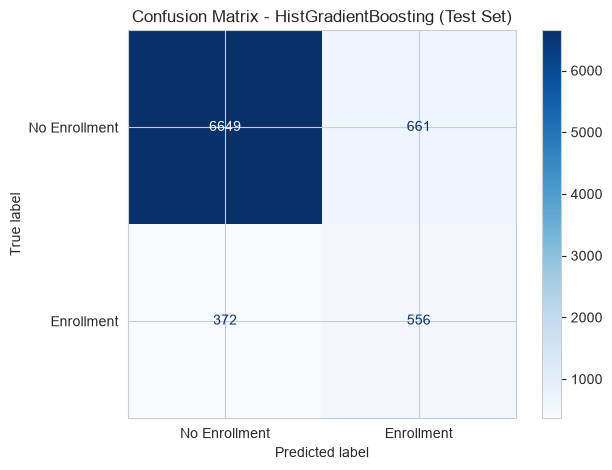

In [27]:
#Final Model Evaluation
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Select final model and threshold
# ------------------------------------------------------------

final_model_name = "HistGradientBoosting"

final_model = tuned_models[final_model_name]
final_threshold = selected_thresholds[final_model_name]

print(f"Final Model: {final_model_name}")
print(f"Selected Threshold: {final_threshold:.4f}")


# ------------------------------------------------------------
# 2. Fit final model on the full training set
# ------------------------------------------------------------

final_model.fit(X_train_baseline, y_train)

cols_in = final_model.named_steps["preprocessing"].feature_names_in_
assert "contact_interval_group" in cols_in
assert "number_days_since_last" not in cols_in


# ------------------------------------------------------------
# 3. Generate probabilities and predictions on the test set
# ------------------------------------------------------------

y_test_proba = final_model.predict_proba(X_test_baseline)[:, 1]

y_test_pred = (
    y_test_proba >= final_threshold
).astype(int)


# ------------------------------------------------------------
# 4. Evaluate final test performance
# ------------------------------------------------------------

test_ap = average_precision_score(
    y_test,
    y_test_proba
)

test_roc_auc = roc_auc_score(
    y_test,
    y_test_proba
)

test_precision = precision_score(
    y_test,
    y_test_pred
)

test_recall = recall_score(
    y_test,
    y_test_pred
)

test_f1 = f1_score(
    y_test,
    y_test_pred
)

predicted_positive_rate = y_test_pred.mean()


print("\nTest Set Performance")
print("-" * 35)

print(f"Average Precision:       {test_ap:.4f}")
print(f"ROC-AUC:                 {test_roc_auc:.4f}")
print(f"Precision:               {test_precision:.4f}")
print(f"Recall:                  {test_recall:.4f}")
print(f"F1-score:                {test_f1:.4f}")
print(
    f"Predicted Positive Rate: "
    f"{predicted_positive_rate:.2%}"
)


# ------------------------------------------------------------
# 5. Classification report
# ------------------------------------------------------------
print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=["No Enrollment", "Enrollment"],
        zero_division=0
    )
)


# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=["No Enrollment", "Enrollment"],
    cmap="Blues",
    values_format="d"
)

plt.title("Confusion Matrix - HistGradientBoosting (Test Set)")
plt.tight_layout()
plt.show()

The final HistGradientBoosting model achieves an AP of **0.4754** and a ROC-AUC of **0.8051** on the test set. Since the enrollment rate is approximately **11.27%**, a non-informative ranking would have an AP of about **0.113**. The model therefore achieves an AP roughly **4.2 times the baseline**, indicating meaningful ability to rank likely enrollees above non-enrollees. Using the threshold of **0.1841** selected from out-of-fold training predictions to maximize F1-score, the model achieves **45.7% precision, 59.9% recall, and an F1-score of 0.5184**. It predicts **14.8%** of test clients as likely to enroll. The confusion matrix shows that the model correctly identifies **556 of 928 actual enrollees**, while missing **372**. Among non-enrollees, **6,649 are correctly classified** and **661 are incorrectly flagged as likely enrollees**. The results are also consistent with cross-validation performance. Test AP (**0.4754**) is slightly higher than the cross-validation AP (**0.4609**), while test F1 (**0.5184**) is slightly higher than the out-of-fold F1 (**0.4960**). This suggests that there is no evidence of a material performance drop on unseen data, although some difference between cross-validation and test performance is expected due to sampling variation.

### 2.8 Robustness Checks
We perform three robustness checks on the selected HistGradientBoosting model: duplicate-overlap sensitivity, bootstrap confidence intervals for test performance, and an ablation analysis excluding `number_contacts`.

#### 2.8.1 Duplicate-Overlap Sensitivity

In [28]:
# Dplicate-Overlap Sensitivity
import numpy as np
import pandas as pd

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    f1_score
)


# Convert target to aligned Series
y_train_series = pd.Series(
    np.asarray(y_train),
    index=X_train.index,
    name="enroll"
)

y_test_series = pd.Series(
    np.asarray(y_test),
    index=X_test.index,
    name="enroll"
)


# Reconstruct complete records: features + target
train_records = pd.concat(
    [X_train, y_train_series],
    axis=1
).reset_index(drop=True)

test_records = pd.concat(
    [X_test, y_test_series],
    axis=1
).reset_index(drop=True)


# Hash complete records to identify exact train-test overlap
train_hashes = set(
    pd.util.hash_pandas_object(
        train_records,
        index=False
    )
)

test_hashes = pd.util.hash_pandas_object(
    test_records,
    index=False
)

overlap_mask = test_hashes.isin(train_hashes).to_numpy()
non_overlap_mask = ~overlap_mask


print(
    f"Exact duplicate test records also found in training: "
    f"{overlap_mask.sum():,} / {len(overlap_mask):,} "
    f"({overlap_mask.mean():.2%})"
)


# Final-model predictions from Section 2.7
y_test_array = np.asarray(y_test)

y_test_pred = (
    y_test_proba >= final_threshold
).astype(int)


# Full test-set performance
full_metrics = {
    "N": len(y_test_array),
    "AP": average_precision_score(
        y_test_array,
        y_test_proba
    ),
    "ROC-AUC": roc_auc_score(
        y_test_array,
        y_test_proba
    ),
    "F1": f1_score(
        y_test_array,
        y_test_pred
    )
}


# Performance after removing overlapping duplicate records
non_overlap_metrics = {
    "N": non_overlap_mask.sum(),
    "AP": average_precision_score(
        y_test_array[non_overlap_mask],
        y_test_proba[non_overlap_mask]
    ),
    "ROC-AUC": roc_auc_score(
        y_test_array[non_overlap_mask],
        y_test_proba[non_overlap_mask]
    ),
    "F1": f1_score(
        y_test_array[non_overlap_mask],
        y_test_pred[non_overlap_mask]
    )
}


duplicate_check = pd.DataFrame(
    {
        "Full Test Set": full_metrics,
        "Non-Overlapping Test Set": non_overlap_metrics
    }
).T


display(
    duplicate_check.style.format({
        "N": "{:.0f}",
        "AP": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "F1": "{:.4f}"
    })
)

Exact duplicate test records also found in training: 829 / 8,238 (10.06%)


,N,AP,ROC-AUC,F1
Full Test Set,8238,0.4754,0.8051,0.5184
Non-Overlapping Test Set,7409,0.4812,0.8011,0.5196


Among the 8,238 test observations, 829 (10.06%) have exact duplicates in the training set. After removing these overlapping records, AP changes only from **0.4754 to 0.4812**, ROC-AUC from **0.8051 to 0.8011**, and F1-score from **0.5184 to 0.5196**. These changes are very small, indicating that train-test duplicate overlap is not materially driving the reported test performance.

#### 2.8.2 Bootstrap Confidence Intervals

In [29]:
# Bootstrap Confidence Intervals
n_bootstrap = 2000
rng = np.random.default_rng(42)

bootstrap_ap = []
bootstrap_auc = []

n_test = len(y_test_array)


for _ in range(n_bootstrap):

    # Resample test observations with replacement
    sample_idx = rng.integers(
        0,
        n_test,
        size=n_test
    )

    y_boot = y_test_array[sample_idx]
    prob_boot = y_test_proba[sample_idx]

    # ROC-AUC requires both classes
    if len(np.unique(y_boot)) < 2:
        continue

    bootstrap_ap.append(
        average_precision_score(
            y_boot,
            prob_boot
        )
    )

    bootstrap_auc.append(
        roc_auc_score(
            y_boot,
            prob_boot
        )
    )


# Observed test performance
observed_ap = average_precision_score(
    y_test_array,
    y_test_proba
)

observed_auc = roc_auc_score(
    y_test_array,
    y_test_proba
)


# 95% percentile bootstrap confidence intervals
ap_ci = np.percentile(
    bootstrap_ap,
    [2.5, 97.5]
)

auc_ci = np.percentile(
    bootstrap_auc,
    [2.5, 97.5]
)


bootstrap_summary = pd.DataFrame({
    "Metric": [
        "Average Precision",
        "ROC-AUC"
    ],
    "Observed": [
        observed_ap,
        observed_auc
    ],
    "95% CI Lower": [
        ap_ci[0],
        auc_ci[0]
    ],
    "95% CI Upper": [
        ap_ci[1],
        auc_ci[1]
    ]
})


display(
    bootstrap_summary.style.format({
        "Observed": "{:.4f}",
        "95% CI Lower": "{:.4f}",
        "95% CI Upper": "{:.4f}"
    })
)

,Metric,Observed,95% CI Lower,95% CI Upper
0,Average Precision,0.4754,0.4417,0.5120
1,ROC-AUC,0.8051,0.7882,0.8219


Bootstrap resampling of the test set produces a **95% confidence interval of [0.4417, 0.5120] for AP** and **[0.7882, 0.8219] for ROC-AUC**. The observed values, AP = **0.4754** and ROC-AUC = **0.8051**, lie near the center of these intervals, suggesting that the model's ranking performance is relatively stable with respect to sampling variation in the test set.

#### 2.8.3 Ablation: Excluding number_contacts

In [30]:
# ablavtion: excluding number_contacts
from sklearn.base import clone
from sklearn.model_selection import cross_validate, cross_val_predict
from sklearn.metrics import (average_precision_score, roc_auc_score,
                             f1_score, precision_recall_curve)

# 1. Drop the feature not available before the campaign
drop_cols = ["number_contacts"]
X_train_abl = X_train_baseline.drop(columns=drop_cols)
X_test_abl = X_test_baseline.drop(columns=drop_cols)

# 2. Same tuned HGB pipeline (hyperparameters not re-tuned)
abl_model = clone(tuned_models["HistGradientBoosting"])

# 3a. CV performance
abl_cv = cross_validate(
    abl_model, X_train_abl, y_train, cv=cv,
    scoring={"AP": "average_precision", "ROC-AUC": "roc_auc"}, n_jobs=-1
)

# 3b. OOF threshold (F1-maximizing, same rule as main model)
abl_oof = cross_val_predict(
    abl_model, X_train_abl, y_train, cv=cv, method="predict_proba", n_jobs=-1
)[:, 1]
p, r, t = precision_recall_curve(y_train, abl_oof)
f1_curve = 2 * p[:-1] * r[:-1] / np.maximum(p[:-1] + r[:-1], 1e-12)
abl_threshold = t[np.argmax(f1_curve)]

# 3c. Fit on full train, evaluate on test
abl_model.fit(X_train_abl, y_train)
abl_proba = abl_model.predict_proba(X_test_abl)[:, 1]

# Lift helper
def top_share_lift(y, proba, share):
    y = np.asarray(y)
    n = int(np.ceil(len(y) * share))
    top = np.argsort(-proba)[:n]
    return y[top].mean() / y.mean()

# Full-model CV numbers (recomputed with the same cv for a like-for-like comparison)
full_cv = cross_validate(
    clone(tuned_models["HistGradientBoosting"]), X_train_baseline, y_train, cv=cv,
    scoring={"AP": "average_precision", "ROC-AUC": "roc_auc"}, n_jobs=-1
)

def summarize(cv_res, proba, thr):
    return {
        "CV AP": cv_res["test_AP"].mean(),
        "CV ROC-AUC": cv_res["test_ROC-AUC"].mean(),
        "Test AP": average_precision_score(y_test, proba),
        "Test ROC-AUC": roc_auc_score(y_test, proba),
        "Threshold": thr,
        "Test F1": f1_score(y_test, (proba >= thr).astype(int)),
        "Top 10% Lift": top_share_lift(y_test, proba, 0.10),
        "Top 20% Lift": top_share_lift(y_test, proba, 0.20),
    }

ablation_df = pd.DataFrame({
    "Full model": summarize(full_cv, y_test_proba, final_threshold),
    "Without number_contacts": summarize(abl_cv, abl_proba, abl_threshold),
}).T

ablation_df.loc["Change"] = ablation_df.iloc[1] - ablation_df.iloc[0]
display(ablation_df.round(4))

,CV AP,CV ROC-AUC,Test AP,Test ROC-AUC,Threshold,Test F1,Top 10% Lift,Top 20% Lift
Full model,0.4609,0.7941,0.4754,0.8051,0.1841,0.5184,4.7295,3.2589
Without number_contacts,0.4592,0.7916,0.4743,0.8068,0.1929,0.5208,4.6648,3.2751
Change,-0.0017,-0.0025,-0.0010,0.0017,0.0089,0.0024,-0.0646,0.0162


Excluding `number_contacts` produces only minor changes in model performance. CV AP decreases from **0.4609 to 0.4592**, while test AP changes from **0.4754 to 0.4743**. Test ROC-AUC increases slightly from **0.8051 to 0.8068**, and F1-score from **0.5184 to 0.5208**. Top-10% lift decreases from **4.73 to 4.66**, while top-20% lift remains essentially unchanged (**3.26 to 3.28**). These small differences suggest that the model's predictive performance does not materially depend on `number_contacts`. The implications for feature availability at prediction time are discussed further in **4.1**.

### 2.9 Feature Importance and Feature Relationships

We use permutation importance and a mixed-type association heatmap to examine feature importance and relationships among predictors. These results support interpretation rather than causal inference; **correlation does not imply causation**.

#### 2.9.1 Permutation Importance

We calculate permutation importance on the test set using **AP**, consistent with the primary model-selection metric. The analysis is performed at the **original-feature level**, so any engineered transformations derived from a permuted feature are affected through the preprocessing pipeline as well.

In [31]:
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# Permutation importance
# ------------------------------------------------------------

perm_result = permutation_importance(
    final_model,
    X_test_baseline,
    y_test,
    scoring="average_precision",
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)


# ------------------------------------------------------------
# Store results
# ------------------------------------------------------------

feature_importance = pd.DataFrame({
    "Feature": X_test_baseline.columns,
    "Importance": perm_result.importances_mean,
    "Std": perm_result.importances_std
}).sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)


display(
    feature_importance.style.format({
        "Importance": "{:.4f}",
        "Std": "{:.4f}"
    })
)

,Feature,Importance,Std
0,enroll_previous,0.1395,0.0058
1,cci,0.1284,0.0070
2,contact_channel,0.0833,0.0047
3,cpi,0.0503,0.0045
4,number_contacts,0.0093,0.0026
5,contact_interval_group,0.0080,0.0027
6,day_of_week,0.0067,0.0026
7,month,0.0059,0.0024
8,credit_in_default,0.0033,0.0018
9,education_level,0.0025,0.0010


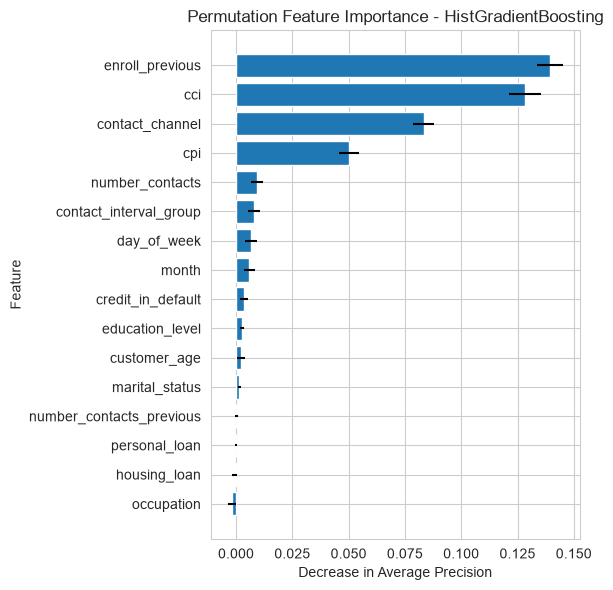

In [32]:
# Plot all 16 features
plot_df = feature_importance.sort_values("Importance")

plt.figure(figsize=(6, 6))

plt.barh(
    plot_df["Feature"],
    plot_df["Importance"],
    xerr=plot_df["Std"]
)

plt.xlabel("Decrease in Average Precision")
plt.ylabel("Feature")
plt.title("Permutation Feature Importance - HistGradientBoosting")

plt.tight_layout()
plt.show()

Permutation importance shows that **enroll_previous**, **CCI**, **contact_channel**, and **CPI** are the most important predictors, reducing AP by approximately **0.139**, **0.128**, **0.083**, and **0.050**, respectively. The remaining features have substantially smaller permutation importance, with `number_contacts` and `contact_interval_group` forming a distant second tier.

#### 2.9.2 Heatmap

We use a mixed-type association matrix to examine relationships among the most important features identified by permutation importance. The full association heatmap across all 16 original features is provided in the Appendix **A.8**.

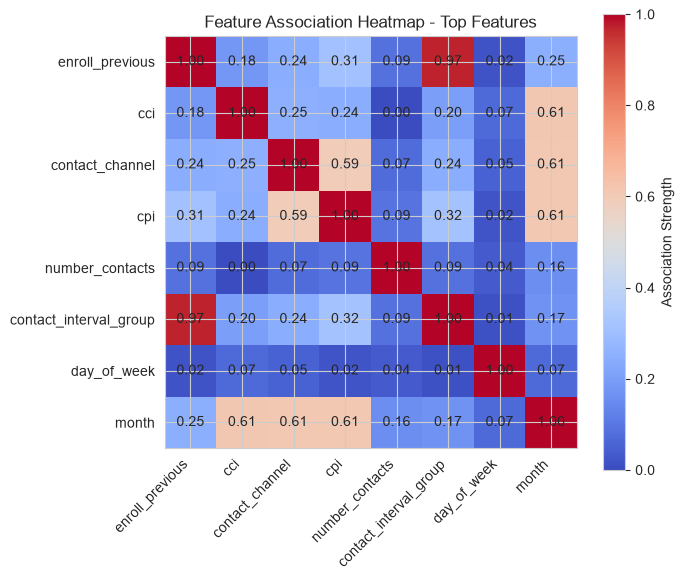

In [33]:
from scipy.stats import chi2_contingency


# ============================================================
# Helper functions
# ============================================================

def cramers_v(x, y):
    table = pd.crosstab(x, y)

    chi2 = chi2_contingency(
        table,
        correction=False
    )[0]

    n = table.values.sum()
    r, k = table.shape

    if min(r - 1, k - 1) == 0:
        return 0

    return np.sqrt(
        (chi2 / n) / min(r - 1, k - 1)
    )


def correlation_ratio(categories, values):
    categories = pd.Series(categories).reset_index(drop=True)
    values = pd.Series(values).reset_index(drop=True)

    overall_mean = values.mean()

    numerator = 0

    for category in categories.unique():
        group = values[
            categories == category
        ]

        numerator += (
            len(group)
            * (group.mean() - overall_mean) ** 2
        )

    denominator = (
        (values - overall_mean) ** 2
    ).sum()

    if denominator == 0:
        return 0

    return np.sqrt(
        numerator / denominator
    )


def association_matrix(df):

    cols = df.columns

    result = pd.DataFrame(
        np.eye(len(cols)),
        index=cols,
        columns=cols
    )

    for i in range(len(cols)):

        for j in range(i + 1, len(cols)):

            x = df.iloc[:, i]
            y = df.iloc[:, j]

            x_num = pd.api.types.is_numeric_dtype(x)
            y_num = pd.api.types.is_numeric_dtype(y)

            # Numerical vs numerical
            if x_num and y_num:

                value = abs(
                    x.corr(
                        y,
                        method="spearman"
                    )
                )

            # Categorical vs categorical
            elif not x_num and not y_num:

                value = cramers_v(
                    x,
                    y
                )

            # Numerical vs categorical
            elif x_num:

                value = correlation_ratio(
                    y,
                    x
                )

            else:

                value = correlation_ratio(
                    x,
                    y
                )

            result.iloc[i, j] = value
            result.iloc[j, i] = value

    return result


# ============================================================
# Association heatmap for top features
# ============================================================

top_features = feature_importance["Feature"].head(8).tolist()

assoc_top = association_matrix(
    X_train_baseline[top_features]
)

fig, ax = plt.subplots(
    figsize=(7, 6)
)

im = ax.imshow(
    assoc_top,
    vmin=0,
    vmax=1,
    cmap="coolwarm"
)

ax.set_xticks(
    range(len(top_features))
)

ax.set_xticklabels(
    top_features,
    rotation=45,
    ha="right"
)

ax.set_yticks(
    range(len(top_features))
)

ax.set_yticklabels(
    top_features
)

for i in range(len(top_features)):
    for j in range(len(top_features)):

        ax.text(
            j,
            i,
            f"{assoc_top.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

fig.colorbar(
    im,
    ax=ax,
    label="Association Strength"
)

ax.set_title(
    "Feature Association Heatmap - Top Features"
)

plt.tight_layout()
plt.show()

The strongest association is between `enroll_previous` and `contact_interval_group` (**0.97**). `month` also shows moderate associations with `CCI`, `contact_channel`, and `CPI` (approximately **0.61**), while most other relationships among the top features are relatively weak.

### 2.10 Why Is This Approach Suitable?

**1. The model choice is supported by patterns identified during EDA.**
The exploratory analysis suggests that several predictors have relationships with enrollment that are not easily represented by simple linear effects. For example, CPI and CCI show non-monotonic relationships with enrollment, age and contact frequency exhibit nonlinear patterns, and enrollment rates vary across combinations such as month and contact channel. Tree-based models are well suited to this structure because they can learn nonlinear relationships and interactions directly from the data without requiring them to be specified manually.

**2. Model complexity is justified through comparison rather than assumed in advance.**
The analysis begins with simple benchmarks, including a Dummy Classifier and Logistic Regression, and then compares several tree-based models under the same validation framework. HistGradientBoosting achieves the highest mean cross-validated AP, although the differences among the ensemble models are small and the paired fold comparison shows only a modest advantage. Because AP is the primary model-selection metric, HistGradientBoosting is retained as the final model, while the similar performance across ensemble methods suggests that the main predictive conclusions are not dependent on a single algorithm.

**3. The reliability of the results is examined through robustness checks.**
Training and validation performance are compared to identify potential overfitting, bootstrap confidence intervals quantify uncertainty in the test-set metrics, a sensitivity analysis examines whether train–test duplicate overlap materially affects performance, and an ablation analysis evaluates performance without `number_contacts`.

**4. The evaluation strategy is appropriate for the imbalanced target.**
Only approximately **11.27%** of clients enroll, making accuracy a poor primary metric. AP is therefore used as the main model-selection metric, with ROC-AUC as a complementary measure of ranking performance. Precision, recall, and F1-score are then used to evaluate classification performance at the selected operating threshold.

**5. Model selection, threshold selection, and final evaluation are kept separate.**
Hyperparameters are selected using stratified cross-validation on the training data, while the classification threshold is chosen using out-of-fold training predictions. The test set is reserved for final evaluation.

**6. The approach supports both practical targeting and model interpretation.**
The final model produces enrollment probabilities that can be used to rank clients by predicted likelihood of enrollment, allowing targeting decisions to be adjusted according to campaign capacity, cost, or business priorities.

## 3. Business Recommendations

The business question is: **How can a financial institution use predictive modeling to identify clients who are more likely to enroll in a product and improve campaign targeting?**

To answer this question, we focus on three practical questions:

1. **Who should be targeted?**
2. **How much improvement can model-based targeting provide?**
3. **How should the model be tested and used in practice?**

### 3.1 Targeting Strategy: Who Should Be Targeted?

Customers are ranked by predicted enrollment probability. We compare the top 10%, 20%, 30%, and 40% of ranked customers with the overall customer population, and also evaluate the group selected by the F1-optimized threshold.

In [34]:
# Create targeting dataframe
targeting_df = pd.DataFrame({
    "actual": np.asarray(y_test),
    "predicted_probability": y_test_proba
}).sort_values("predicted_probability", ascending=False).reset_index(drop=True)

# Overall enrollment rate
overall_rate = targeting_df["actual"].mean()

# Evaluate several campaign capacities
target_shares = [0.10, 0.20, 0.30, 0.40]

targeting_summary = []

for share in target_shares:
    n_target = int(np.ceil(len(targeting_df) * share))
    targeted = targeting_df.iloc[:n_target]

    targeting_summary.append({
        "Target Share": f"Top {int(share * 100)}%",
        "Customers Targeted": n_target,
        "Enrollment Rate": targeted["actual"].mean()
    })

targeting_summary = pd.DataFrame(targeting_summary)

# Add full-population benchmark
targeting_summary.loc[len(targeting_summary)] = {
    "Target Share": "All Customers",
    "Customers Targeted": len(targeting_df),
    "Enrollment Rate": overall_rate
}

# Display percentages
targeting_summary["Enrollment Rate"] = (
    targeting_summary["Enrollment Rate"] * 100
).round(2)

display(targeting_summary)

,Target Share,Customers Targeted,Enrollment Rate
0,Top 10%,824,53.28
1,Top 20%,1648,36.71
2,Top 30%,2472,27.47
3,Top 40%,3296,21.94
4,All Customers,8238,11.26


In [35]:
# Targeting implied by the selected classification threshold

threshold_target = y_test_proba >= final_threshold

threshold_summary = pd.DataFrame({
    "Selected Threshold": [final_threshold],
    "Customers Targeted": [threshold_target.sum()],
    "Target Share": [threshold_target.mean()],
    "Enrollment Rate": [y_test[threshold_target].mean()]
})

threshold_summary["Selected Threshold"] = (
    threshold_summary["Selected Threshold"].round(4)
)

threshold_summary["Target Share"] = (
    threshold_summary["Target Share"] * 100
).round(2)

threshold_summary["Enrollment Rate"] = (
    threshold_summary["Enrollment Rate"] * 100
).round(2)

display(threshold_summary)

,Selected Threshold,Customers Targeted,Target Share,Enrollment Rate
0,0.1841,1217,14.77,45.69


### Finding and Recommendation

Enrollment is strongly concentrated among customers ranked highest by the model. The overall enrollment rate is **11.26%**, compared with **53.28%** among the top 10% of customers and **36.71%** among the top 20%. The F1-optimized threshold of **0.1841** selects **1,217 customers**, representing **14.77%** of the test population, with an observed enrollment rate of **45.69%**.

**Recommendation:** Rather than contacting the full customer base uniformly, the campaign should prioritize customers with the highest predicted enrollment probabilities. A practical initial strategy is to focus outreach on approximately the **top 10–20% of customers**, with the exact cutoff adjusted according to campaign capacity, contact cost, and business objectives.

### 3.2 Expected Campaign Lift: How Much Improvement Can Model-Based Targeting Provide?

We calculate cumulative gain and cumulative lift by ranking customers in descending order of predicted enrollment probability and comparing model-based targeting with random targeting.

,Target Share,Enrollments Captured (%),Cumulative Lift
0,Top 10%,47.31,4.73
1,Top 20%,65.19,3.26
2,Top 30%,73.17,2.44
3,Top 40%,77.91,1.95


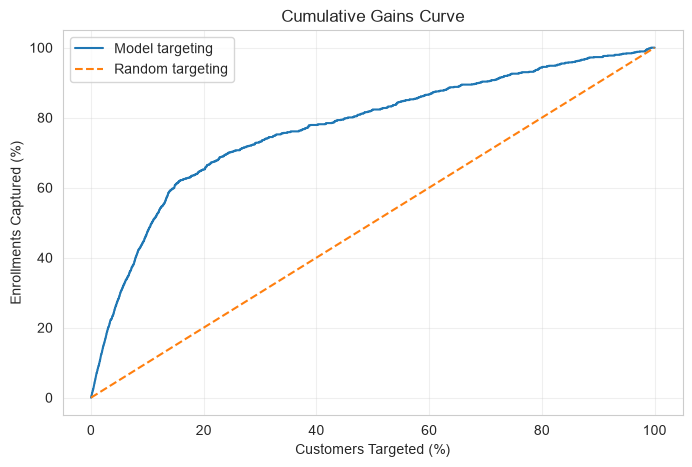

In [36]:
#Cumulative Gain and Lift
gain_df = targeting_df.copy()

n_customers = len(gain_df)
total_enrollments = gain_df["actual"].sum()

# Position of each customer in the ranked population
gain_df["customers_targeted"] = np.arange(1, n_customers + 1)

# Share of customers contacted
gain_df["population_share"] = (
    gain_df["customers_targeted"] / n_customers
)

# Cumulative number of actual enrollments captured
gain_df["cumulative_enrollments"] = (
    gain_df["actual"].cumsum()
)

# Share of all actual enrollments captured
gain_df["cumulative_gain"] = (
    gain_df["cumulative_enrollments"] / total_enrollments
)

# Cumulative lift relative to random targeting
gain_df["cumulative_lift"] = (
    gain_df["cumulative_gain"] / gain_df["population_share"]
)
target_shares = [0.10, 0.20, 0.30, 0.40]

gain_summary = []

for share in target_shares:
    idx = int(np.ceil(n_customers * share)) - 1
    row = gain_df.iloc[idx]

    gain_summary.append({
        "Target Share": f"Top {int(share * 100)}%",
        "Enrollments Captured (%)": row["cumulative_gain"] * 100,
        "Cumulative Lift": row["cumulative_lift"]
    })

gain_summary = pd.DataFrame(gain_summary)

gain_summary["Enrollments Captured (%)"] = (
    gain_summary["Enrollments Captured (%)"].round(2)
)

gain_summary["Cumulative Lift"] = (
    gain_summary["Cumulative Lift"].round(2)
)

display(gain_summary)

plt.figure(figsize=(8, 5))

plt.plot(
    gain_df["population_share"] * 100,
    gain_df["cumulative_gain"] * 100,
    label="Model targeting"
)

plt.plot(
    [0, 100],
    [0, 100],
    linestyle="--",
    label="Random targeting"
)

plt.xlabel("Customers Targeted (%)")
plt.ylabel("Enrollments Captured (%)")
plt.title("Cumulative Gains Curve")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Finding and Recommendation

The model concentrates a large share of actual enrollments among a relatively small portion of customers. Targeting only the **top 10%** of customers captures **47.31%** of all observed enrollments, corresponding to a cumulative lift of **4.73** relative to random targeting. Expanding outreach to the **top 20%** captures **65.19%** of enrollments, with a cumulative lift of **3.26**. The gains curve also shows diminishing returns as the campaign expands to lower-ranked customers. Additional outreach continues to capture more enrollments, but the incremental benefit becomes smaller as the targeting share increases.

**Recommendation:** If outreach capacity is limited, the campaign should concentrate resources on the highest-ranked customers rather than expanding broadly across the full customer base. The **top 10–20%** provides a strong initial targeting range, capturing approximately **47–65% of observed enrollments** while contacting only a small fraction of customers. The final campaign size should depend on outreach cost, available capacity, and the value of additional enrollments.

### 3.3 Deployment and Campaign Testing: How Should the Model Be Used and Tested in Future Campaigns?

For each new campaign population, the trained model can generate an enrollment probability for every eligible customer. Customers can then be ranked by predicted probability, and the campaign can select the highest-ranked customers according to available outreach capacity and budget. This allows the targeting size to change across campaigns without requiring a fixed classification threshold.

Before full deployment, the targeting strategy should be validated through a controlled campaign test. A randomly selected portion of eligible customers can be divided into a **model-targeted group** and a **business-as-usual or random-targeting group**. The two groups can then be compared using business outcomes such as enrollment rate, incremental enrollments, and cost per enrollment.

**Recommendation:** Deploy the model first through a limited pilot campaign rather than immediately replacing the existing targeting process. If model-based targeting produces a consistent improvement in enrollment and campaign efficiency, it can then be expanded to a larger share of customers. Model performance and enrollment patterns should also be monitored over time, with periodic retraining if customer behavior or campaign conditions change.

## 4. Limitations

We consider four main limitations:

1. **Data and feature limitations (Sections 4.1–4.3)**
2. **Generalizability (Sections 4.4–4.5)**
3. **Model and experiment coverage (Section 4.6)**
4. **From prediction to production (Sections 4.7–4.9)**

### 4.1 Feature Availability at Prediction Time
Some predictors may not be available at the time a client is scored. In particular, `number_contacts` records the number of contacts made during the current campaign and may therefore be unavailable for pre-campaign targeting. To assess the practical impact of this limitation, Section **2.8.3** re-evaluates the model after excluding `number_contacts`. Performance changes only marginally: CV AP decreases from **0.4609 to 0.4592**, test AP from **0.4754 to 0.4743**, and the ranking and lift metrics remain very similar. This suggests that a pre-campaign version of the model could exclude `number_contacts` with little loss in predictive performance.

### 4.2 Ambiguity in `number_days_since_last`

The definition of `number_days_since_last = 999` is not fully consistent with the observed data. Sections **1.4.2** and **1.5** examine and address this issue by separating these observations into `never_contacted` and `un_retrievable`. The exact meaning of 999 is not documented beyond the provided data dictionary. Our treatment is therefore based on the available evidence in the data and may not fully recover the true meaning of the original records. This remaining ambiguity may introduce measurement error into the model.

### 4.3 Duplicate and Conflicting Observations

Duplicate observations appear across the training and test sets, but the sensitivity analysis in Section **2.8.1** shows that removing this overlap has little effect on model performance. However, identical observed feature profiles can still have different enrollment outcomes, indicating that the available predictors do not fully explain enrollment behavior.


### 4.4 Temporal Validation, Macroeconomic Regimes, and External Validity

The current stratified random split may not fully represent future deployment because observations from different time periods can appear in both training and test sets. Features such as `month`, `cpi`, and `cci` may also capture period-specific economic conditions, so performance on the current test set may overstate generalization to future periods or different populations. With reliable timestamps, future work should use temporal validation by training on earlier observations and evaluating on later ones. Validation on newer periods or external customer populations would provide stronger evidence of generalizability.

### 4.5 Historical Targeting and Population Selection Bias

The dataset contains customers selected under the bank's historical targeting strategy, so the training population may not represent the broader customer base. If the model is applied to customers who were historically not targeted, differences in population characteristics could reduce predictive performance. Future deployment should therefore begin with populations similar to the historical data and expand gradually while monitoring performance as the target population changes.

### 4.6 Model and Experiment Coverage

The analysis covers several representative models, but the modeling and hyperparameter search space is not exhaustive, so stronger alternatives may still exist. Future work could explore broader hyperparameter searches, additional boosting methods, model ensembling, and richer feature representations.

### 4.7 Prediction vs. Incremental Campaign Impact

The model predicts which customers are more likely to enroll, but it does not estimate whether contact itself causes the enrollment. A high predicted probability therefore does not necessarily imply a large incremental campaign effect. Future work should validate model-based targeting through randomized A/B testing and, if incremental response is the main objective, consider uplift modeling or treatment-effect estimation.

### 4.8 Decision Threshold, Probability Calibration, and Business Costs

The F1-optimized threshold is a statistical choice and may not maximize business value because campaign capacity, contact cost, customer value, and error costs are not included in the current analysis. Future deployment should select targeting cutoffs using business costs and expected value, and probability calibration should be evaluated if predicted probabilities are used directly for financial decisions.

### 4.9 Responsible Deployment: Fairness and Monitoring

The model may produce different targeting patterns across customer groups, and its performance may change as customer behavior, campaign strategy, or economic conditions evolve. Before and after deployment, selection rates and predictive performance should be monitored across relevant groups, together with feature drift, calibration, and overall model performance, with retraining or recalibration when needed.

## Appendix

### A.1 Treatment of `"unknown"` Categories

Several categorical features contain `"unknown"` values, most notably `credit_in_default` (20.9%). We retain `"unknown"` as an explicit category rather than imputing or dropping these observations, because the absence of recorded information may itself be informative and this approach avoids introducing assumptions about the underlying true values. It also preserves all observations, which is important given the relatively high unknown rate in some features. These categories are subsequently handled through one-hot encoding together with the other categorical levels. Alternative treatments, such as imputation or dropping the feature, could be considered as robustness checks if necessary.

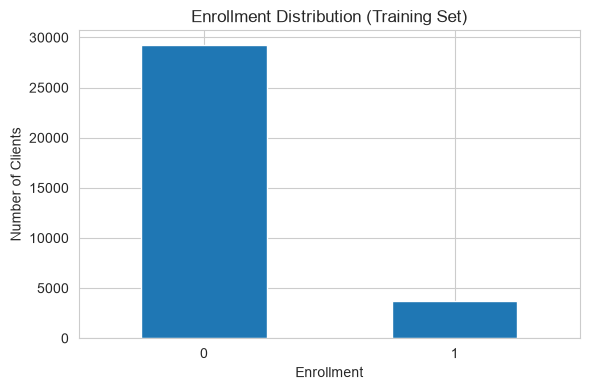

In [37]:
import matplotlib.pyplot as plt

train_eda["enroll"].value_counts().plot(
    kind="bar",
    figsize=(6, 4)
)

plt.title("Enrollment Distribution (Training Set)")
plt.xlabel("Enrollment")
plt.ylabel("Number of Clients")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### A.2 Target Distribution

We examine the distribution of the target variable (`enroll`) in the training set to assess potential class imbalance.

Class imbalance is important for model development because a model may achieve high overall accuracy by predominantly predicting the majority class. Therefore, we will consider precision, recall, F1-score, and PR-AUC in addition to accuracy when evaluating model performance.

### A.3 Economic Indicators and Enrollment

The table below provides the detailed bin-level results underlying the CPI and CCI enrollment-rate plots shown in Section 1.4.2. The continuous values are divided into quantile-based ranges, with the number of observations and enrollment rate reported for each range.

In [38]:
# Detailed enrollment rates by economic indicators

def format_range(row):
    interval = row["cpi"] if row["feature"] == "CPI" else row["cci"]
    return f"{interval.left:.2f} – {interval.right:.2f}"

economic_table = pd.DataFrame({
    "Feature": economic_indicator_summary["feature"],
    "Range": economic_indicator_summary.apply(format_range, axis=1),
    "Count": economic_indicator_summary["size"],
    "Enrollment Rate (%)": (economic_indicator_summary["mean"] * 100).round(2),
})

display(economic_table)

,Feature,Range,Count,Enrollment Rate (%)
0,CPI,92.20 – 92.89,6647,18.10
1,CPI,92.89 – 93.44,9749,10.85
2,CPI,93.44 – 93.92,5730,9.42
3,CPI,93.92 – 93.99,6175,3.00
4,CPI,93.99 – 94.77,4649,15.62
5,CCI,-50.80 – -46.20,7105,13.79
6,CCI,-46.20 – -42.00,8252,5.93
7,CCI,-42.00 – -40.00,4557,14.33
8,CCI,-40.00 – -36.40,6792,7.08
9,CCI,-36.40 – -26.90,6244,17.76


### A.4 Detailed Enrollment Rates by Categorical Feature

The following tables report the sample size and enrollment rate for each category of the categorical features summarized in the main EDA section.

In [39]:
categorical_cols = [
    "occupation",
    "contact_channel",
    "enroll_previous",
    "month",
    "marital_status",
    "education_level",
    "credit_in_default",
    "housing_loan",
    "personal_loan"
]

for col in categorical_cols:
    summary = (
        train_eda.groupby(col)["enroll_binary"]
        .agg(
            Count="size",
            Enrollment_Rate="mean"
        )
        .sort_values("Enrollment_Rate", ascending=False)
    )

    summary["Enrollment_Rate"] *= 100

    print(f"\n{col}")
    display(summary.round(2))


occupation


,Count,Enrollment_Rate
occupation,,
student,711,30.52
retired,1366,25.48
unemployed,798,14.54
admin,8314,12.87
unknown,265,12.45
management,2345,11.47
technician,5400,10.83
self_employed,1099,10.83
homemaker,855,10.06



contact_channel


,Count,Enrollment_Rate
contact_channel,,
email,20908,14.7
phone,12042,5.3



enroll_previous


...

,Count,Enrollment_Rate
credit_in_default,,
no,26007,12.88
unknown,6940,5.20
yes,3,0.00



housing_loan


,Count,Enrollment_Rate
housing_loan,,
yes,17254,11.56
unknown,796,11.31
no,14900,10.93



personal_loan


,Count,Enrollment_Rate
personal_loan,,
unknown,796,11.31
no,27131,11.27
yes,5023,11.23


### A.5 Binned Analysis of Selected Numerical Features

To further examine potential nonlinear relationships, `customer_age` and `number_contacts` are grouped into interpretable ranges. The figures below show the enrollment rate across these groups.

,mean,size
age_group,,
"(0, 25]",0.208,1346
"(25, 35]",0.117,11882
"(35, 45]",0.085,10247
"(45, 55]",0.088,6614
"(55, 65]",0.149,2371
"(65, 120]",0.469,490


,mean,size
contact_group,,
1,0.129,14121
2,0.116,8469
3,0.108,4300
4-5,0.087,3371
6-10,0.066,2002
11+,0.029,687


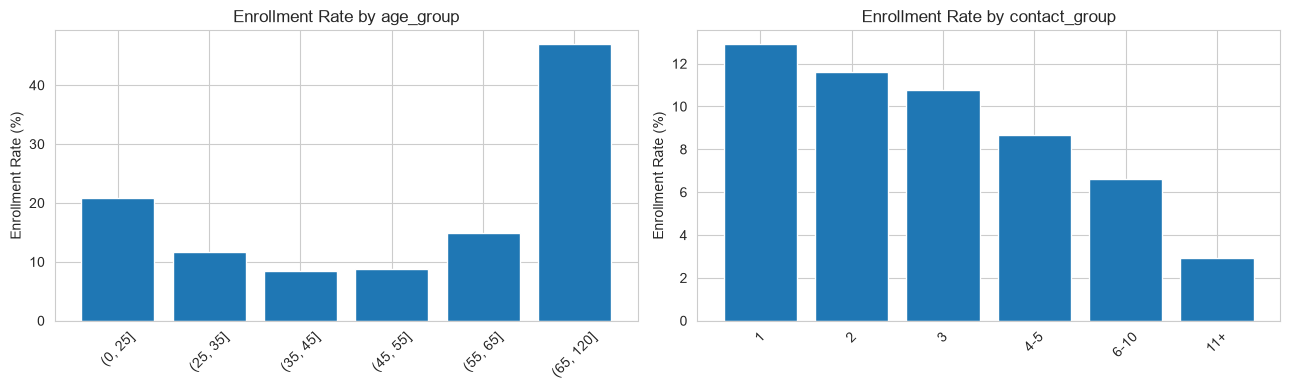

In [40]:
train_eda["age_group"] = pd.cut(
    train_eda["customer_age"],
    bins=[0, 25, 35, 45, 55, 65, 120]
)

train_eda["contact_group"] = pd.cut(
    train_eda["number_contacts"],
    bins=[0, 1, 2, 3, 5, 10, float("inf")],
    labels=["1", "2", "3", "4-5", "6-10", "11+"]
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, col in zip(
    axes,
    ["age_group", "contact_group"]
):
    summary = (
        train_eda.groupby(col, observed=True)["enroll"]
        .agg(["mean", "size"])
    )

    ax.bar(summary.index.astype(str), summary["mean"] * 100)
    ax.set_title(f"Enrollment Rate by {col}")
    ax.set_ylabel("Enrollment Rate (%)")
    ax.tick_params(axis="x", rotation=45)

    display(summary.round(3))

plt.tight_layout()
plt.show()

### A.6 Evaluation Metrics

Because only about **11.27%** of clients enroll in the product, ordinary accuracy can be misleading. A classifier that predicts "no enrollment" for every client would achieve approximately **88.73% accuracy** while identifying none of the enrolled clients. We therefore use metrics that better reflect performance on the positive class and distinguish between threshold-independent and threshold-based evaluation.

**Average Precision (AP)**

Average Precision is the primary metric for model comparison and hyperparameter tuning. It summarizes the precision-recall relationship across classification thresholds:

$$
AP = \sum_n (R_n - R_{n-1})P_n,
$$

where $P_n$ and $R_n$ are precision and recall at the $n$-th threshold:

$$
\text{Precision} = \frac{TP}{TP+FP},
\qquad
\text{Recall} = \frac{TP}{TP+FN}.
$$

AP is particularly useful for imbalanced classification because it focuses on performance for the positive class. Intuitively, AP is higher when enrolled clients tend to receive higher model scores and appear near the top of the ranking. The positive-class prevalence, approximately **0.1127**, provides a natural reference level for AP.

**ROC-AUC**

ROC-AUC is reported as a secondary threshold-independent metric. It measures the model's ability to rank an enrolled client above a non-enrolled client across all possible classification thresholds. A value of **0.5** corresponds to random ranking, while **1.0** represents perfect discrimination.

**Threshold-Based Metrics**

Accuracy, Balanced Accuracy, Precision, Recall, and F1 depend on a specific classification threshold. Because some candidate models use class weighting while others do not, their predicted probability scales can differ. A common threshold such as 0.5 therefore does not provide a fully comparable basis for model selection.

Accuracy is defined as:

$$
\text{Accuracy}
=
\frac{TP+TN}{TP+TN+FP+FN}.
$$

Balanced Accuracy gives equal weight to the two classes:

$$
\text{Balanced Accuracy}
=
\frac{1}{2}
\left(
\frac{TP}{TP+FN}
+
\frac{TN}{TN+FP}
\right).
$$

This makes it more informative than ordinary accuracy under class imbalance. For example, predicting every client as negative would produce approximately **88.73% Accuracy** but only **0.5 Balanced Accuracy**.

Precision measures the proportion of predicted enrollees who actually enroll:

$$
\text{Precision}
=
\frac{TP}{TP+FP}.
$$

Recall measures the proportion of actual enrollees identified by the model:

$$
\text{Recall}
=
\frac{TP}{TP+FN}.
$$

F1 is the harmonic mean of Precision and Recall:

$$
F1
=
2
\frac{\text{Precision}\times\text{Recall}}
{\text{Precision}+\text{Recall}}.
$$

**Threshold Selection**

After the final model is selected primarily using cross-validated AP, its operating threshold is selected separately. Out-of-fold predictions from the training data are used to choose the threshold that maximizes F1. The held-out test set is not used in either model selection or threshold selection.

F1 is used because the available data do not provide explicit business costs for false positives and false negatives. The resulting threshold should therefore be interpreted as a practical classification rule rather than a business-optimal decision threshold.

### A.7 Overfitting Safeguards

Several safeguards against overfitting are incorporated throughout the modeling process. Hyperparameter tuning uses **5-fold stratified cross-validation**, and all preprocessing steps are fitted separately within each training fold to avoid information leakage.

For the tree-based models, complexity-related hyperparameters such as tree depth, minimum leaf size, and regularization parameters are tuned through cross-validation rather than allowing unrestricted model complexity. HistGradientBoosting additionally uses **early stopping**, which can stop boosting when additional iterations no longer improve validation performance.

### A.8 Full Feature Association Heatmap

The full mixed-type association matrix across all 16 original features is shown below. The corresponding analysis of the most important features is presented in Section 2.9.2.

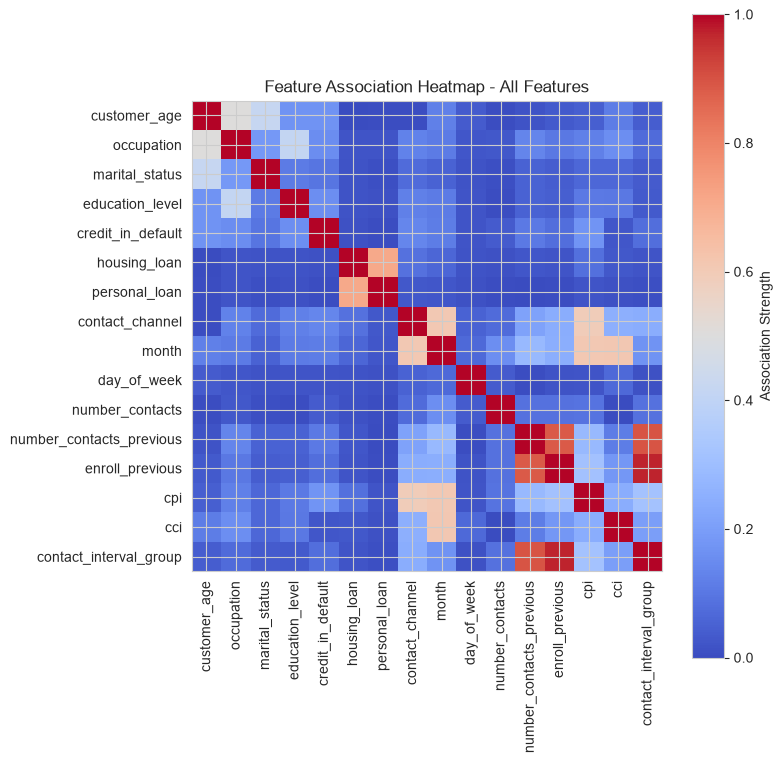

In [41]:
from scipy.stats import chi2_contingency


# ============================================================
# Helper functions
# ============================================================

def cramers_v(x, y):
    table = pd.crosstab(x, y)

    chi2 = chi2_contingency(
        table,
        correction=False
    )[0]

    n = table.values.sum()
    r, k = table.shape

    if min(r - 1, k - 1) == 0:
        return 0

    return np.sqrt(
        (chi2 / n) / min(r - 1, k - 1)
    )


def correlation_ratio(categories, values):
    categories = pd.Series(categories).reset_index(drop=True)
    values = pd.Series(values).reset_index(drop=True)

    overall_mean = values.mean()

    numerator = 0

    for category in categories.unique():
        group = values[
            categories == category
        ]

        numerator += (
            len(group)
            * (group.mean() - overall_mean) ** 2
        )

    denominator = (
        (values - overall_mean) ** 2
    ).sum()

    if denominator == 0:
        return 0

    return np.sqrt(
        numerator / denominator
    )


def association_matrix(df):

    cols = df.columns

    result = pd.DataFrame(
        np.eye(len(cols)),
        index=cols,
        columns=cols
    )

    for i in range(len(cols)):

        for j in range(i + 1, len(cols)):

            x = df.iloc[:, i]
            y = df.iloc[:, j]

            x_num = pd.api.types.is_numeric_dtype(x)
            y_num = pd.api.types.is_numeric_dtype(y)

            # Numerical vs numerical
            if x_num and y_num:

                value = abs(
                    x.corr(
                        y,
                        method="spearman"
                    )
                )

            # Categorical vs categorical
            elif not x_num and not y_num:

                value = cramers_v(
                    x,
                    y
                )

            # Numerical vs categorical
            elif x_num:

                value = correlation_ratio(
                    y,
                    x
                )

            else:

                value = correlation_ratio(
                    x,
                    y
                )

            result.iloc[i, j] = value
            result.iloc[j, i] = value

    return result


# ============================================================
# Association heatmap for all 16 features
# ============================================================

assoc_all = association_matrix(
    X_train_baseline
)

fig, ax = plt.subplots(
    figsize=(8, 8)
)

im = ax.imshow(
    assoc_all,
    vmin=0,
    vmax=1,
    cmap="coolwarm"
)

ax.set_xticks(
    range(len(assoc_all.columns))
)

ax.set_xticklabels(
    assoc_all.columns,
    rotation=90
)

ax.set_yticks(
    range(len(assoc_all.index))
)

ax.set_yticklabels(
    assoc_all.index
)

fig.colorbar(
    im,
    ax=ax,
    label="Association Strength"
)

ax.set_title(
    "Feature Association Heatmap - All Features"
)

plt.tight_layout()
plt.show()